# Timestral, zero-shot

This notebook asks one question: **can a pretrained forecasting model, used as it comes, forecast the size of Bitcoin's hourly moves as well as the models trained on our data?** The model is Timestral, the family of time-series foundation models that Mistral released on 15 October 2026. *Zero-shot* means that its weights never see our data: the notebook only chooses, on the validation block, which series the model reads, how much history, which covariates and which model size.

## Main results

| Question | Timestral (chosen on validation) | Test result | Classical reference (refitted here) | Verdict |
|---|---|---|---|---|
| Size of each of the next 24 hours (\|r\|) | average of Timestral 28M (\|r\|, 180 days, clock + releases + range and volume + ETH size + VIX) and Gradient Boosting refitted every month | R² **0.164** (Timestral alone 0.157; Gradient Boosting with Timestral's forecast as a column 0.155–0.157) | Gradient Boosting refitted every month: R² 0.148 | **better (+0.016, reliable)**; Timestral alone +0.009, reliable |
| 80% range for each hour | Timestral's own q10–q90 (+ rolling conformal) | coverage 80.3% raw (79.9% calibrated), width 1.00%, **release hours 70%**; all 21 quantiles calibrated within 1.4 points | Gradient Boosting quantile + rolling conformal: coverage 79.9%, width 0.98%, release hours 56% | tie overall, without any calibration; **better in release hours (+13.8 points, reliable)** |
| 24 hourly returns (the median of the forecast) | Timestral, series r | MAE skill −0.0014 | zero forecast (Gradient Boosting q50: −0.0007) | nothing beats predicting 0% |

**In short:** used as it comes, with nothing fitted on our data, the smallest Timestral forecasts the size of Bitcoin's hourly moves better than every single model trained on it: R² 0.157, against 0.148 for Gradient Boosting refitted every month and 0.156 for the best network of `neural-models.ipynb`, an LSTM fine-tuned every month. Averaged with Gradient Boosting it reaches 0.164; given to Gradient Boosting as a column instead, it does worse (0.155–0.157). Neither ETH, the order flow, the VIX nor a GARCH forecast adds anything. Its 80% ranges, and its whole forecast distribution, are honest without calibration, and in release hours they are wider and cover 70% of the moves, against 56% for the classical ranges. The returns themselves stay unpredictable. The caveat below applies: the test block may be in Timestral's training data.

## Timestral

| | |
|---|---|
| **Models** | 5M, 28M, 123M and 209M parameters, one architecture; weights of 21 MB, 111 MB, 490 MB and 837 MB (fp32) |
| **Output** | 21 quantiles (1%, 5%, 10%, …, 90%, 95%, 99%) of every forecast step |
| **Inputs** | the target series (NaN = missing), past-only covariates and known-future covariates (numbers, 0/1 indicators or categories) |
| **Context** | up to 32,768 steps, read in patches of 32 steps: the 24 predicted hours are one patch |
| **Training** | mostly synthetic series, then a mix of real and synthetic series that Mistral does not list |
| **Code and weights** | `github.com/mistralai/timestral` (Apache 2.0, inference only) · Hugging Face `mistralai/Timestral-28M`, `-209M`, … (modified MIT license) |

**Setup.** Besides `data/btc_hourly.csv.gz` and the release calendar, the notebook reads the Binance files `data/binance_BTCUSDT_1h.csv.gz` and `data/binance_ETHUSDT_1h.csv.gz` and the macro file `data/macro_raw.csv.gz` (VIX), already used by the other notebooks. `pip install -r requirements.txt` installs the `timestral` package, pinned to a commit of its GitHub repository. The weights are downloaded to the Hugging Face cache the first time a model is used: `MODEL` (28M, 111 MB) and the models of `EXTRA_MODELS` (empty by default; 209M is 837 MB). Every Timestral forecast, every fitted Gradient Boosting model (`fit_cached`, in `data/timestral_cache/models/`) and the monthly refits are saved in `data/timestral_cache/` (`CACHE_DIR`), so a rerun only computes what changed; a model saved in `models/` by an earlier run is loaded instead of refitted when it has the same setting and data.

## What is chosen, and how

Nothing is trained, but there are still choices. All of them are made on the validation block (Jan 2023 → Jun 2024):

| Choice | Options | Stage |
|---|---|---|
| input series | the hourly return r, or its size \|r\| | A |
| context | the last 30, 90 or 180 days | A |
| covariates | clock (as categories or as numbers), release hours (B5), range and volume of each past hour, then ETH size, order flow, VIX and a GARCH forecast | B: one group at a time, kept if the validation R² improves |
| model size | 28M; optionally the chosen setting with a larger model (`EXTRA_MODELS`, off by default) | C |
| rescaling | none, or \|r\| ≈ a + b × forecast, fitted on train origins (refitted on train + validation for the test) | every run |
| combination with Gradient Boosting | plain average, or Timestral's forecast (mean, 21 quantiles) and a GARCH forecast as columns of Gradient Boosting | 3.3–3.4 |

Of Timestral itself only the rescaling is fitted on our data: two numbers. The chosen setting is then run **once** on the test block. The averages of Timestral and Gradient Boosting are candidates from the start and are chosen on validation like the rest (`neural-models.ipynb`, section 8.4, explains why a choice made after looking at the test is not a result).

## Caveat: the test block may be in the training data

Timestral was released after the end of our test block (8 Oct 2026), and Mistral does not say which real series it used. If Bitcoin prices of 2023–2026 are among them, the validation and test blocks are not out-of-sample for the model, and its results here may be optimistic. This cannot be checked from outside.

## Rules

The rules of `classical-models.ipynb` and `neural-models.ipynb`: the same data (1 Jan 2020 → 8 Oct 2026), forecast origins, blocks (cut by the date of the predicted hours, with a 192-hour purge before each border) and test days, so every number here can be compared with theirs. The classical references are refitted here on the same rows, so the differences can be tested with the block bootstrap.

**Run time:** under two hours from scratch on an RTX 5060 Laptop GPU (8 GB), most of it Timestral's forecasts (the test block takes 30 min with the chosen covariates) and the monthly Gradient Boosting refits (CPU). The run of 26 Oct 2026, with the forecasts of the first run cached, took 79 minutes. Forecasts and fitted models are cached in `data/timestral_cache/`, so a rerun takes a few minutes.

## 1. Settings, data and blocks

*Setup: to see the results, skip to section 3.*

Run the notebook from the repo root, so that `data/` and `utils/` are found. Sections 1.1–1.3 repeat sections 1.1–1.3 of `neural-models.ipynb`, so the forecast origins, the blocks and the long-format rows are identical.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # conda's MKL numpy and pip's torch each ship libiomp5md.dll (model_test.ipynb)
import glob
import hashlib
import json
import re
import sys
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.optimize import minimize
from scipy.signal import lfilter
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from timestral import TimestralForecaster

sys.path.insert(0, os.getcwd())   # utils/ is in the repo root
from utils import hourly as U
from utils.binance import load_binance
from utils.config import DATA_START, TEST_START, VAL_START
from utils.features import TARGET_HOUR_FEATURES, load_releases, target_hour_features
from utils.macro import align_levels, load_macro
from utils.saving import ModelSaver

DATA_PATH = os.path.join("data", "btc_hourly.csv.gz")
WINDOW = pd.Timedelta(hours=192)            # purge before each border (168 input + 24 target hours, versions 2-3)
STRIDE = 6                                  # train and validation keep every 6th forecast origin
RANDOM_STATE = 42
MODEL = "mistralai/Timestral-28M"           # stages A and B (111 MB download)
EXTRA_MODELS = []                           # stage C: the chosen setting with larger models, e.g. ["mistralai/Timestral-209M"]
                                            # (837 MB; run of 25 Oct 2026: val R2 +0.005 for 7x the time, section 3.2)
REVISIONS = {}                              # {repo: Hugging Face commit hash}, to pin the weights of a rerun
CONTEXTS = (720, 2160, 4320)                # hours of history the model reads: 30, 90 and 180 days
BATCH = 256                                 # rows (origins x series and covariates) per forward pass: Timestral's
                                            # attention across rows is quadratic in this number (8 GB GPU)
RUN_GB_REFIT = True                         # Gradient Boosting refitted every month (about 15 min of CPU, then cached)
Q_STRIDE = 6                                # section 4 keeps every 6th test origin: ranges need far fewer rows than R2
CACHE_DIR = os.path.join("data", "timestral_cache")   # forecasts saved here, so a rerun loads them; None turns it off
EXPORT_DIR = "models"                       # section 3.7 saves the models in EXPORT_DIR/<name of the best model>/
SAVE_MODELS = True                          # the other trained models (section 4) go to models/timestral-zero-shot/
save = ModelSaver("timestral-zero-shot", enabled=SAVE_MODELS)   # save(name, model) -> model (utils/saving.py)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
T_START = time.time()
np.random.seed(RANDOM_STATE)
print(f"PyTorch {torch.__version__}, device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

# Colours and axes style shared by the plots (as in classical-models.ipynb)
BLUE, ORANGE, AQUA, GREY, INK, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#b4b2a9", "#52514e", "#6250d6"


def tidy(ax, title=None):
    if title:
        ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def digest(a):
    # short fingerprint of an array, for the cache keys
    return hashlib.md5(np.ascontiguousarray(a).tobytes()).hexdigest()[:12]


def cached(key, fn):
    # fn() (an array), saved in CACHE_DIR under a hash of `key` (a tuple naming every input), so a rerun loads it
    if CACHE_DIR is None:
        return fn()
    path = os.path.join(CACHE_DIR, hashlib.md5(repr(key).encode()).hexdigest()[:16] + ".npy")
    if os.path.exists(path):
        return np.load(path)
    out = fn()
    os.makedirs(CACHE_DIR, exist_ok=True)
    np.save(path, out)
    return out


def fit_cached(name, make, X, y, sample_weight=None, legacy=None):
    # make() fitted on (X, y), saved in CACHE_DIR/models/ under a hash of its setting and its data, so a rerun loads it
    # instead of fitting it again. legacy(): candidates saved by an earlier run (models/), used if they match (same_fit)
    model = make()
    key = ("model", name, repr(sorted(model.get_params().items())), X.shape, digest(X), digest(y),
           None if sample_weight is None else digest(sample_weight))
    path = None if CACHE_DIR is None else os.path.join(CACHE_DIR, "models", hashlib.md5(repr(key).encode()).hexdigest()[:16] + ".joblib")
    if path is not None and os.path.exists(path):
        return joblib.load(path)
    old = next((m for m in (legacy() if legacy is not None else []) if same_fit(m, model, X, y, sample_weight)), None)
    if old is not None:
        print(f"loaded from an earlier run: {name}")
        model = old
    else:
        model.fit(X, y, sample_weight=sample_weight)
    if path is not None:
        os.makedirs(os.path.dirname(path), exist_ok=True)
        joblib.dump(model, path)
    return model


def same_fit(old, new, X, y, w):
    # an earlier model is the one make() would fit on (X, y) if it has the same setting, the same number of columns,
    # all its trees, and starts from the same constant (the weighted mean or quantile of y: a fingerprint of the target)
    try:
        return (type(old) is type(new) and old.get_params() == new.get_params() and old.n_features_in_ == X.shape[1]
                and old.n_iter_ == new.max_iter
                and np.allclose(old._baseline_prediction, old._loss.fit_intercept_only(y_true=y, sample_weight=w)))
    except (AttributeError, TypeError, ValueError):
        return False


def earlier(name):
    # loader of the models saved under `name` by an earlier run: export bundles and models/timestral-zero-shot/
    def load():
        for path in glob.glob(os.path.join(EXPORT_DIR, "*", "models.joblib")):
            m = joblib.load(path).get("models", {}).get(name)
            if hasattr(m, "predict"):
                yield m
        if name in save.names():
            yield save.load(name)
    return load

PyTorch 2.14.1+cu130, device: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)


### 1.1 Data and forecast origins

As in `neural-models.ipynb` (section 1.1): `Return` in percent, every hour with 30 days of history and 24 hours after it is a forecast origin, and `y_all[i, h]` is the return of hour *h* + 1 after origin *i*. The features are computed only to find the same first origin and for the Gradient Boosting references; Timestral reads the hourly series itself (section 2).

In [2]:
hourly = pd.read_csv(DATA_PATH, index_col="Timestamp", parse_dates=True).loc[DATA_START:].copy()
hourly["Return"] *= U.PCT
assert (hourly.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "the hourly grid has holes"
ret, absr = hourly["Return"].values, hourly["Return"].abs().values

F_base, F_b1, F_b2 = U.base_features(hourly), U.long_lookback_features(hourly), U.range_vol_features(hourly)
FEAT = pd.concat([F_base, F_b1, F_b2], axis=1)
BASE = list(F_base.columns)

# forecast origins: every hour with all features defined (30 days of history) and 24 hours after it
ok = np.isfinite(FEAT.values).all(axis=1)
first = int(np.argmax(ok))
assert ok[first:].all(), "missing feature values inside the series"
pos_all = np.arange(first, len(hourly) - U.H_AHEAD)
origins = hourly.index[pos_all]
y_all = np.stack([ret[pos_all + k] for k in range(1, U.H_AHEAD + 1)], axis=1)     # next 24 returns, %

releases = load_releases()
B5 = list(TARGET_HOUR_FEATURES)
print(f"{len(hourly):,} hours   {hourly.index[0]} -> {hourly.index[-1]}")
print(f"{len(origins):,} forecast origins   {origins[0]} -> {origins[-1]}")

59,331 hours   2020-01-01 00:00:00 -> 2026-10-08 02:00:00
58,588 forecast origins   2020-01-30 23:00:00 -> 2026-10-07 02:00:00


### 1.2 The three blocks

As in `neural-models.ipynb` (section 1.2): train and validation keep every 6th origin, test keeps every origin, and `test_days` (one origin per day, at 23:00) are the independent days of the bootstrap. One more set is added:

- **`cal`**: every 5th train origin (one every 30 hours, so the hour of the origin rotates), on which the optional rescaling of Timestral's forecast is fitted. Two numbers need far fewer rows than a model, and each Timestral run forecasts these origins too.

In [3]:
start_hour = origins + pd.Timedelta(hours=1)              # first predicted hour
day_end = origins + pd.Timedelta(hours=U.H_AHEAD)         # last predicted hour
in_train = np.flatnonzero(day_end < VAL_START - WINDOW)
in_val = np.flatnonzero((start_hour >= VAL_START) & (day_end < TEST_START - WINDOW))
blk = {
    "train": in_train[::STRIDE],
    "val": in_val[::STRIDE],
    "test": np.flatnonzero(start_hour >= TEST_START),
}
blk["tv"] = np.r_[blk["train"], blk["val"]]                # train + validation (refit of the chosen models)
blk["cal"] = blk["train"][::5]                             # train origins for the rescaling of Timestral (section 3.2)
P = {k: pos_all[v] for k, v in blk.items()}               # positions in the hourly series
Y = {k: y_all[v] for k, v in blk.items()}                 # next 24 returns, %
D = {k: origins[v] for k, v in blk.items()}               # origin timestamps
test_days = np.arange(0, len(P["test"]), 24)              # one origin per day (23:00) -> independent days
assert (D["test"][test_days].hour == 23).all()
ND = len(test_days)

display(pd.DataFrame({
    "origins": {k: len(P[k]) for k in P},
    "first origin": {k: D[k][0] for k in P},
    "last origin": {k: D[k][-1] for k in P},
    "avg |hourly move| %": {k: np.abs(Y[k]).mean() for k in P},
}))
print(f"independent test days: {ND}")

,origins,first origin,last origin,avg |hourly move| %
train,4229,2020-01-30 23:00:00,2022-12-22 23:00:00,0.502392
val,2153,2022-12-31 23:00:00,2024-06-21 23:00:00,0.301283
test,19876,2024-06-30 23:00:00,2026-10-07 02:00:00,0.319275
tv,6382,2020-01-30 23:00:00,2024-06-21 23:00:00,0.434547
cal,846,2020-01-30 23:00:00,2022-12-22 05:00:00,0.504209


independent test days: 829


### 1.3 Long format and the inputs of the references

The long format of `neural-models.ipynb` (section 1.3): every origin becomes 24 rows, one per predicted hour, in origin-major order, so a Timestral forecast of shape (origins, 24) flattened row by row lines up with them. The Gradient Boosting references use the set chosen on validation in `classical-models.ipynb` (section 6.4) and `neural-models.ipynb` (section 5.1), **base + B3**. `rule_abs` is the best simple rule, last week's average \|r\| × the hour-of-day profile.

In [4]:
H_BASE = ["h_ahead", "tgt_hour_sin", "tgt_hour_cos", "tgt_dow_sin", "tgt_dow_cos"]
B3 = ["tgt_weekend", "tgt_hour_profile", "absret_same_hour_1d", "absret_same_hour_7d", "ret_same_hour_1d"]
REL = ["tgt_cpi", "tgt_payrolls", "tgt_fomc", "tgt_after_fomc"]     # release hours (classical-models.ipynb, section 7)
tr_abs = hourly["Return"].abs().loc[D["train"][0]: D["train"][-1] + pd.Timedelta(hours=U.H_AHEAD)]
HOUR_PROFILE = (tr_abs.groupby(tr_abs.index.hour).mean() / tr_abs.mean()).values
week_abs = pd.Series(absr).rolling(168).mean().values               # last week's average |r| at each hour
TGT = target_hour_features(hourly.index, releases)                  # B5 of every hour (known in advance)


def Xl(block, cols, hcols=H_BASE):
    # Long format: 24 rows per origin (origin-major order); cols = origin features, hcols = per-hour features
    p = P[block]
    base = np.repeat(FEAT[cols].values[p], 24, axis=0)
    h_ = np.tile(np.arange(1, 25), len(p))
    tp = np.repeat(p, 24) + h_                                       # position of the predicted hour
    t = hourly.index[tp]
    extra = {
        "h_ahead": h_,
        "tgt_hour_sin": np.sin(2 * np.pi * t.hour / 24), "tgt_hour_cos": np.cos(2 * np.pi * t.hour / 24),
        "tgt_dow_sin": np.sin(2 * np.pi * t.dayofweek / 7), "tgt_dow_cos": np.cos(2 * np.pi * t.dayofweek / 7),
        "tgt_weekend": (t.dayofweek >= 5).astype(float),
        "tgt_hour_profile": HOUR_PROFILE[t.hour],
        "absret_same_hour_1d": absr[tp - 24], "absret_same_hour_7d": absr[tp - 168],
        "ret_same_hour_1d": ret[tp - 24],
    }
    return np.hstack([base, np.column_stack([extra[c] for c in hcols])])


def yl(block, kind="abs"):
    v = Y[block].reshape(-1)
    return np.abs(v) if kind == "abs" else v


def rule_abs(block):
    # Baseline: last week's average |r| x hour-of-day profile of the predicted hour
    p = np.repeat(P[block], 24)
    h_ = np.tile(np.arange(1, 25), len(P[block]))
    return week_abs[p] * HOUR_PROFILE[hourly.index[p + h_].hour]


def release_rows(block):
    # Long-format rows whose predicted hour is a release hour (CPI, payrolls, FOMC, or 1-2 h after FOMC)
    tp = np.repeat(P[block], 24) + np.tile(np.arange(1, 25), len(P[block]))
    return TGT[REL].values[tp].any(axis=1)


def rows24(idx):
    return (np.asarray(idx)[:, None] * 24 + np.arange(24)).ravel()


safe_corr = U.safe_corr
ya = {k: yl(k) for k in P}                                           # |r| of the 24 predicted hours, long format
XA = {k: Xl(k, BASE, H_BASE + B3) for k in ("train", "val", "test", "tv")}
SUMMARY = []

### 1.4 A volatility model: GARCH

A classical model of expected volatility, used in section 3.4 as a column of Gradient Boosting and in section 3.2 as a covariate of Timestral. The returns are first divided by the hour-of-day profile, so the model sees no daily rhythm, and the variance of each hour follows σ²ₜ = ω + α·xₜ₋₁ + β·σ²ₜ₋₁, with two choices of x:

- **GARCH(1,1)**: x is the squared return;
- **range GARCH**: x is the Parkinson variance of the hour's High–Low range, a more precise measure of the same thing (`utils/hourly.py`, B2).

Both are fitted by Gaussian likelihood on the train hours only (up to the purge before validation) and forecast h hours ahead with the usual mean reversion to the long-run variance. The expected \|r\| of hour t + h is the hour profile × E\|z\| × σₜ₊ₕ, where E\|z\| is the mean size of the standardized train residuals. The model with the better validation R² is kept (`GARCH_CHOSEN`). Fitting takes about a second, and there is no refit later.
**What we see.** Neither model is a good forecast of the size of the next hours on its own: validation R² 0.005 for GARCH(1,1) and −0.017 for the range GARCH, against 0.050 for the simple rule (last week × hour profile) and 0.095 for Gradient Boosting; on test GARCH(1,1) reaches 0.038 (section 3.1). The likelihood fits the variance of the returns, which is driven by a few very large hours, rather than the typical size of a move that R² rewards, and the train hours of 2020–2022 were wilder than the later blocks. GARCH(1,1) is kept (`GARCH_CHOSEN`) as a candidate input; sections 3.2 and 3.4 decide on validation whether it adds anything.

In [5]:
t0 = time.time()
HOUR = np.asarray(hourly.index.hour)
e_ds = ret / HOUR_PROFILE[HOUR]                                      # returns without the daily rhythm
lhl = np.log(hourly["High"] / hourly["Low"]).clip(lower=0).values * U.PCT
DRIVES = {"GARCH(1,1)": e_ds ** 2, "range GARCH": lhl ** 2 / (4 * np.log(2)) / HOUR_PROFILE[HOUR] ** 2}
GARCH_END = int(np.searchsorted(hourly.index, VAL_START - WINDOW))   # fitted on the train hours only


def garch_var(params, drive):
    # s2[t]: variance of hour t given the hours before it; s2[t + 1] is known at the end of hour t
    w, a, b = params
    s2 = np.empty(len(drive) + 1)
    s2[0] = drive[:720].mean()
    s2[1:] = lfilter([1.0], [1.0, -b], w + a * drive, zi=[b * s2[0]])[0]
    return s2


def garch_fit(drive):
    def nll(p):
        w, a, b = p
        if w <= 0 or a < 0 or b < 0 or a + b >= 1:
            return 1e12
        s2 = garch_var(p, drive[:GARCH_END])[24:GARCH_END]
        return 0.5 * np.sum(np.log(s2) + e_ds[24:GARCH_END] ** 2 / s2)
    return minimize(nll, [0.05 * e_ds[:GARCH_END].var(), 0.08, 0.9], method="Nelder-Mead",
                    options={"maxiter": 3000, "xatol": 1e-8, "fatol": 1e-5}).x


GARCH = {}
for name, drive in DRIVES.items():
    p = garch_fit(drive)
    s2 = garch_var(p, drive)
    k = drive[:GARCH_END].mean() / s2[:GARCH_END].mean()            # E[x] / E[s2]: 1 for the squared return
    per = p[1] * k + p[2]                                            # persistence of the variance
    GARCH[name] = {"params": p, "s2": s2, "per": per, "V": p[0] / (1 - per),
                   "c": np.mean(np.abs(e_ds[24:GARCH_END]) / np.sqrt(s2[24:GARCH_END]))}


def garch_abs(block, name=None):
    # expected |r| of the 24 predicted hours of each origin (long format), from the variance known at the origin
    g = GARCH[name or GARCH_CHOSEN]
    p = np.repeat(P[block], 24)
    h_ = np.tile(np.arange(1, 25), len(P[block]))
    s2h = g["V"] + g["per"] ** (h_ - 1) * (g["s2"][p + 1] - g["V"])
    return HOUR_PROFILE[HOUR[p + h_]] * g["c"] * np.sqrt(s2h)


garch_tab = pd.DataFrame({n: {"omega": g["params"][0], "alpha": g["params"][1], "beta": g["params"][2],
                              "persistence": g["per"], "half-life h": np.log(0.5) / np.log(g["per"]),
                              "val R2": U.r2(ya["val"], garch_abs("val", n))} for n, g in GARCH.items()}).T
GARCH_CHOSEN = garch_tab["val R2"].idxmax()
GARCH_NAME = f"Baseline: {GARCH_CHOSEN} x hour profile"
GARCH_SD = np.sqrt(GARCH[GARCH_CHOSEN]["s2"][1:])                    # at hour t: forecast sigma of hour t + 1
display(garch_tab.round(4))
print(f"chosen on validation: {GARCH_CHOSEN}; the rule last week x hour profile has val R2 "
      f"{U.r2(ya['val'], rule_abs('val')):.4f} ({time.time() - t0:.0f} s)")

,omega,alpha,beta,persistence,half-life h,val R2
"GARCH(1,1)",0.0073,0.0851,0.9108,0.9900,68.6947,0.0051
range GARCH,0.0149,0.1866,0.7901,0.9801,34.5191,-0.0165


chosen on validation: GARCH(1,1); the rule last week x hour profile has val R2 0.0497 (0 s)


## 2. Timestral: inputs and forecasts

*Setup: to see the results, skip to section 3.*

For each forecast origin Timestral reads the last `ctx` hours of one series and returns 21 quantiles for each of the next 24 hours. Before 1 Jan 2020 (`DATA_START`) the series is NaN, which Timestral treats as missing, so the earliest train origins have a shorter history than `ctx`.

| Input | Rows | Kind |
|---|---|---|
| **series** r or \|r\| | the hourly return (%) or its size | target, the `ctx` hours up to the origin |
| **clock, categorical** | hour of day, weekday (codes) | known-future. Timestral replaces each code by the average of the target for that code in the context: for \|r\|, the code of an hour becomes its average size over the context, a recent hour profile |
| **clock, numeric** | sine and cosine of the hour, weekend flag | known-future |
| **releases** | B5: `tgt_cpi`, `tgt_payrolls`, `tgt_fomc`, `tgt_after_fomc`, `tgt_us_session` (0/1) | known-future indicators: the release calendar is fixed in advance |
| **range, volume** | (High − Low) / Close (%), log volume | past-only |
| **ETH size** | \|r\| of ETHUSDT (%, Binance, `utils/binance.py`) | past-only |
| **order flow** | share of taker buys, log number of trades (Binance BTCUSDT) | past-only |
| **VIX** | log VIX, the close that was public at each hour (`utils/macro.py`, point in time) | past-only |
| **GARCH** | forecast σ of the next hour, from the GARCH of section 1.4 | past-only |

Timestral normalizes every row by itself (per patch, causally), so nothing is scaled here: the level of 2020 and the level of 2026 look the same to the model. The forecaster's defaults are kept, including the *symmetric averaging* recommended by Mistral (the forecast of −series, reflected, is averaged with the forecast of the series; this doubles the run time).

**From quantiles to the size of the move.** The models are judged by R², a squared error, so the right single number is the **mean** of \|r\|, not its median. It is the integral of \|Q(τ)\| over the quantile levels τ, computed with the trapezoid rule over the 21 quantiles (flat tails below 1% and above 99%). With the series \|r\| the quantiles are already ≥ 0; with the series r the same formula gives the expected size of a signed move.

In [6]:
PAD = max(CONTEXTS)                                           # NaN hours before the first hour, for the longest context
ext_index = pd.date_range(hourly.index[0] - PAD * pd.Timedelta(hours=1), hourly.index[-1], freq="h")   # padded calendar
ext_hour, ext_dow = np.asarray(ext_index.hour), np.asarray(ext_index.dayofweek)


def padded(a):
    return np.r_[np.full(PAD, np.nan), np.asarray(a, dtype=float)]


hl_pct = ((hourly["High"] - hourly["Low"]) / hourly["Close"]).values * U.PCT
log_vol = np.log1p(hourly["Volume"].clip(lower=0).values)
btc_bn, eth_bn = (load_binance(s).reindex(hourly.index) for s in ("BTCUSDT", "ETHUSDT"))   # data/binance_*_1h.csv.gz
vix = align_levels(load_macro(os.path.join("data", "macro_raw.csv.gz")), pit=True)["VIX"]
log_vix = np.log(vix.reindex(hourly.index, method="ffill", tolerance=pd.Timedelta(days=10)).values)
assert np.isfinite(np.c_[eth_bn["ret"], btc_bn["buy_share"], btc_bn["trades"], log_vix]).all()
SERIES = {"r": padded(ret), "|r|": padded(absr)}
GROUPS = {   # covariate group -> (argument of TimestralForecaster.forecast, rows over the padded hours)
    "clock, categorical": ("categorical_known_covariates", np.vstack([ext_hour, ext_dow]).astype(float)),
    "clock, numeric": ("known_covariates", np.vstack([np.sin(2 * np.pi * ext_hour / 24), np.cos(2 * np.pi * ext_hour / 24),
                                                      (ext_dow >= 5).astype(float)])),
    "releases": ("known_covariates", target_hour_features(ext_index, releases)[B5].values.T.astype(float)),
    "range, volume": ("past_covariates", np.vstack([padded(hl_pct), padded(log_vol)])),
    "ETH size": ("past_covariates", padded(eth_bn["ret"].abs())[None]),
    "order flow": ("past_covariates", np.vstack([padded(btc_bn["buy_share"]), padded(np.log1p(btc_bn["trades"]))])),
    "VIX": ("past_covariates", padded(log_vix)[None]),
    "GARCH": ("past_covariates", padded(GARCH_SD)[None]),
}
assert all(rows.shape[1] == len(ext_index) for _, rows in GROUPS.values())

FC = {}


def forecaster(repo):
    # The Timestral model `repo`, downloaded to the Hugging Face cache on first use
    if repo not in FC:
        FC[repo] = TimestralForecaster.from_pretrained(repo, device=DEVICE, revision=REVISIONS.get(repo))
    return FC[repo]


fc = forecaster(MODEL)
LEVELS = np.array(fc.quantile_levels)
print(f"{MODEL}: {sum(p.numel() for p in fc.model.parameters()) / 1e6:.1f}M parameters, patches of {fc.patch_size} hours, "
      f"context up to {fc.config.context_length:,} hours, {len(LEVELS)} quantiles {LEVELS.round(2).tolist()}")
print(f"covariates: {fc.supports_covariates}, known-future covariates: {fc.supports_known_covariates}")

# weights of the quantiles in the integral of Q(tau) over tau: trapezoid between the levels, flat tails
_lv = np.r_[0.0, LEVELS, 1.0]
QW = (_lv[2:] - _lv[:-2]) / 2
QW[0] += LEVELS[0] / 2
QW[-1] += (1 - LEVELS[-1]) / 2
assert np.isclose(QW.sum(), 1.0)


def expected_abs(q):
    # mean |r| of each predicted hour from its quantiles: (origins, 24, Q) -> (origins, 24)
    return np.abs(q) @ QW


def timestral_quantiles(pos, series, ctx, covs=(), repo=MODEL):
    # Zero-shot forecast of the 24 hours after each origin (positions `pos` in `hourly`): quantiles (origins, 24, Q)
    key = ("timestral", repo, REVISIONS.get(repo), series, ctx, tuple(covs), digest(pos), str(hourly.index[-1]))
    return cached(key, lambda: _forecast_quantiles(pos, series, ctx, covs, repo))


def _forecast_quantiles(pos, series, ctx, covs, repo, batch=BATCH, series_values=None, groups=None):
    # series_values, groups: replace SERIES[series] and GROUPS (the look-ahead check of section 2.1)
    model = forecaster(repo)
    values = SERIES[series] if series_values is None else series_values
    groups = GROUPS if groups is None else groups
    step = max(1, batch // (1 + sum(len(groups[g][1]) for g in covs)))   # origins per pass: `batch` rows in all
    out = []
    for i in range(0, len(pos), step):
        p = np.asarray(pos[i:i + step]) + PAD                        # positions in the padded series
        ctx_idx = p[:, None] + np.arange(-ctx + 1, 1)                 # the ctx hours up to the origin
        all_idx = p[:, None] + np.arange(-ctx + 1, U.H_AHEAD + 1)     # the same and the 24 predicted hours
        kw = {}
        for g in covs:
            arg, rows = groups[g]
            x = rows[:, ctx_idx if arg == "past_covariates" else all_idx].transpose(1, 0, 2)   # (origins, rows, time)
            kw[arg] = x if arg not in kw else np.concatenate([kw[arg], x], axis=1)
        kw = {k: v.astype(np.float64 if k.startswith("categorical") else np.float32) for k, v in kw.items()}
        f = model.forecast(values[ctx_idx].astype(np.float32), prediction_length=U.H_AHEAD, **kw)
        out.append(f.quantiles[:, 0].float().cpu().numpy())
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return np.concatenate(out)


# check on the first validation origins: shapes and the input of the first one
_q = timestral_quantiles(P["val"][:4], "|r|", CONTEXTS[0], tuple(g for g in GROUPS if g != "clock, numeric")
                         if fc.supports_known_covariates else ())
assert _q.shape == (4, U.H_AHEAD, len(LEVELS)) and np.isfinite(_q).all()
assert (np.diff(_q, axis=-1) >= -1e-6).all(), "quantiles must not cross"
print(f"first validation origin {D['val'][0]}: forecast |r| of the next 3 hours {expected_abs(_q)[0, :3].round(3)}, "
      f"actual {np.abs(Y['val'][0, :3]).round(3)}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

mistralai/Timestral-28M: 27.8M parameters, patches of 32 hours, context up to 32,768 hours, 21 quantiles [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]
covariates: True, known-future covariates: True
first validation origin 2022-12-31 23:00:00: forecast |r| of the next 3 hours [0.109 0.097 0.091], actual [0.042 0.127 0.03 ]


### 2.1 Checks: batch invariance and no look-ahead

Timestral forecasts many origins in each forward pass, and in the test block consecutive origins are consecutive hours: the hours that one origin must predict are in the context of the next origins. If the forecast of an origin could see the other rows of its pass, it could see its own future. Two checks on 48 consecutive test origins, with the series \|r\|, 180 days and the covariates clock (categories), releases, and range and volume:

- **Batch invariance.** The forecast must not depend on which origins share a pass: every origin alone, the default passes and a shuffled order must give the same quantiles. Timestral restricts the attention between rows to the rows of one series (`group_ids`), and this checks it.
- **No look-ahead.** The series and the past-only covariates are replaced by random values from the first predicted hour of origin 25 onwards. The forecasts of origins 1–25 must not change. Those of origins 26–48 must change, otherwise the check could not fail.

Nothing here is cached; the check takes a few seconds.

In [7]:
t0 = time.time()
chk_covs = ("clock, categorical", "releases", "range, volume")
chk = P["test"][:48]                                                 # 48 consecutive hourly origins
chk_args = ("|r|", max(CONTEXTS), chk_covs, MODEL)
n_rows = 1 + sum(len(GROUPS[g][1]) for g in chk_covs)
q_ref = _forecast_quantiles(chk, *chk_args)                          # BATCH rows per pass
q_one = _forecast_quantiles(chk, *chk_args, batch=n_rows)            # one origin per pass
perm = np.random.default_rng(RANDOM_STATE).permutation(len(chk))
q_perm = _forecast_quantiles(chk[perm], *chk_args)[np.argsort(perm)]

# random series and past-only covariates from the first predicted hour of origin 25 (index 24) onwards
cut = chk[24] + 1 + PAD                                              # in the padded series
rng = np.random.default_rng(RANDOM_STATE)
fake_series = SERIES["|r|"].copy()
fake_series[cut:] = rng.exponential(1.0, len(fake_series) - cut)
fake_groups = dict(GROUPS)
for g in chk_covs:
    arg, rows = GROUPS[g]
    if arg == "past_covariates":
        rows = rows.copy()
        rows[:, cut:] = rng.normal(0, 3, rows[:, cut:].shape)
        fake_groups[g] = (arg, rows)
q_fake = _forecast_quantiles(chk, *chk_args, series_values=fake_series, groups=fake_groups)

TOL = 1e-4                                                           # float32 on the GPU: tiny differences are rounding
checks = pd.DataFrame({
    "one origin per pass": {"max |difference|": np.abs(q_one - q_ref).max(), "should be": "≈ 0"},
    "shuffled order": {"max |difference|": np.abs(q_perm - q_ref).max(), "should be": "≈ 0"},
    "random future, origins 1-25": {"max |difference|": np.abs(q_fake[:25] - q_ref[:25]).max(), "should be": "≈ 0"},
    "random future, origins 26-48": {"max |difference|": np.abs(q_fake[25:] - q_ref[25:]).max(), "should be": "> 0"},
}).T
display(checks)
assert (checks["max |difference|"].iloc[:3] < TOL).all(), "the forecast depends on the batch or sees the future"
assert checks["max |difference|"].iloc[3] > 100 * TOL, "the random future changed nothing: the check cannot fail"
print(f"batch invariance and no look-ahead: ok (tolerance {TOL}; {time.time() - t0:.0f} s)")

,max |difference|,should be
one origin per pass,0.000004,≈ 0
shuffled order,0.0,≈ 0
"random future, origins 1-25",0.0,≈ 0
"random future, origins 26-48",8.787428,> 0


batch invariance and no look-ahead: ok (tolerance 0.0001; 16 s)


## 3. The size of each hourly move (main experiment)

**Question.** How large will each of the next 24 hourly moves be? The target is **\|r\|, the absolute return of each hour** (%), judged by R², as in `neural-models.ipynb` (section 5) and `classical-models.ipynb` (section 6).

**To beat.** Refitted here, on the same rows (section 3.1):

- **(a) Gradient Boosting fitted once** on train + validation (`neural-models.ipynb`: validation R² 0.0947, test 0.1295);
- **(b) Gradient Boosting refitted every month** with a half-life of 12 months, the variant chosen on validation in both notebooks (validation 0.1005, test **0.1479**), the best classical model for this target.

The best network of `neural-models.ipynb`, the LSTM with hour features and volume attention fine-tuned every month, has test R² 0.156 (section 5.6 there), and its average with Gradient Boosting and the MLP 0.161.

### 3.1 The classical references

The setting of Gradient Boosting is tuned on the base columns with the grid of `neural-models.ipynb` (section 5.1) and fitted with base + B3. The monthly refit uses the logic of the same section: for every month of the validation or test block, Gradient Boosting is refitted on every 6th origin of the whole series whose 24 target hours ended **before the month starts**, with weight `0.5 ** (age in months / 12)`. With `RUN_GB_REFIT = False` this reference is skipped.

In [8]:
make_abs_gb = lambda **p: HistGradientBoostingRegressor(early_stopping=False, max_iter=200, min_samples_leaf=1000,
                                                        random_state=RANDOM_STATE, **p)
t0 = time.time()
grid = [{"learning_rate": lr, "max_depth": d} for lr in (0.05, 0.1) for d in (2, 3, 6)]
X_tr_b, X_va_b = Xl("train", BASE), Xl("val", BASE)
gb_rows = [{**p, "val R2": U.r2(ya["val"], fit_cached(f"|r| GB {p}, base, train", lambda p=p: make_abs_gb(**p), X_tr_b, ya["train"])
                                .predict(X_va_b))} for p in grid]
del X_tr_b, X_va_b
gb_tab = pd.DataFrame(gb_rows).sort_values("val R2", ascending=False)
p_abs_gb = {"learning_rate": float(gb_tab.iloc[0]["learning_rate"]), "max_depth": int(gb_tab.iloc[0]["max_depth"])}
display(gb_tab.round(4))

GB_ABS, GB_REFIT, RULE = "Classical: GB, fitted once", "Classical: GB, monthly, half-life 12 months", "Baseline: last week x hour profile"
make_best = lambda: make_abs_gb(**p_abs_gb)
gb_train = fit_cached(f"{GB_ABS}, train", make_best, XA["train"], ya["train"])
gb_once = fit_cached(f"{GB_ABS}, train + validation", make_best, XA["tv"], ya["tv"], legacy=earlier(GB_ABS))   # export (3.7)
abs_val = {RULE: rule_abs("val"), GARCH_NAME: garch_abs("val"), GB_ABS: gb_train.predict(XA["val"])}
abs_test = {RULE: rule_abs("test"), GARCH_NAME: garch_abs("test"), GB_ABS: gb_once.predict(XA["test"])}

if RUN_GB_REFIT:
    pool = np.arange(len(origins))[::STRIDE]                         # every 6th origin of the whole series
    P["pool"], Y["pool"], D["pool"] = pos_all[pool], y_all[pool], origins[pool]
    X_pool, y_pool = Xl("pool", BASE, H_BASE + B3), yl("pool")
    XA["pool"] = X_pool
    pool_end, pool_origin = np.repeat(day_end[pool], 24), np.repeat(origins[pool], 24)

    def refit_monthly(block, X_b, half_life=12, Xp=None):
        # Every month of the block: Gradient Boosting fitted on the pool rows whose targets are known before the month
        # (Xp: the pool rows with the same columns as X_b; X_pool by default)
        Xp = X_pool if Xp is None else Xp
        org = np.repeat(D[block], 24)
        pred = np.empty(len(X_b))
        for m in pd.period_range(D[block][0], D[block][-1], freq="M"):
            start = m.start_time
            fit = pool_end < start
            w = 0.5 ** ((start - pool_origin[fit]) / pd.Timedelta(days=30.44) / half_life)
            rows_m = (org >= start) & (org < (m + 1).start_time)
            name = f"{GB_REFIT}, {Xp.shape[1]} columns, fitted for {m}"
            pred[rows_m] = fit_cached(name, make_best, Xp[fit], y_pool[fit], np.asarray(w, float)).predict(X_b[rows_m])
        return pred

    for b, store in (("val", abs_val), ("test", abs_test)):
        key = ("gb_refit", b, tuple(sorted(p_abs_gb.items())), tuple(B3), 12, digest(P[b]), str(hourly.index[-1]))
        store[GB_REFIT] = cached(key, lambda: refit_monthly(b, XA[b]))

REFS = [k for k in (GB_ABS, GB_REFIT) if k in abs_val]
display(pd.DataFrame({k: {"val R2": U.r2(ya["val"], abs_val[k]), "test R2": U.r2(ya["test"], abs_test[k])}
                      for k in [RULE, GARCH_NAME] + REFS}).T.round(4))
print(f"setting {p_abs_gb}; neural-models.ipynb: GB fitted once 0.0947 / 0.1295, refitted monthly 0.1005 / 0.1479 "
      f"(validation / test) ({time.time() - t0:.0f} s)")

,learning_rate,max_depth,val R2
5,0.10,6,0.0966
2,0.05,6,0.0959
1,0.05,3,0.0932
4,0.10,3,0.0921
3,0.10,2,0.0915
0,0.05,2,0.0901


,val R2,test R2
Baseline: last week x hour profile,0.0497,0.0560
"Baseline: GARCH(1,1) x hour profile",0.0051,0.0381
"Classical: GB, fitted once",0.0947,0.1295
"Classical: GB, monthly, half-life 12 months",0.1005,0.1479


setting {'learning_rate': 0.1, 'max_depth': 6}; neural-models.ipynb: GB fitted once 0.0947 / 0.1295, refitted monthly 0.1005 / 0.1479 (validation / test) (4 s)


### 3.2 Choosing the Timestral setting on validation

Every run forecasts the `cal` origins (train) and the validation origins with one setting, and scores the validation block twice: the raw forecast, and the forecast rescaled with \|r\| ≈ a + b × forecast fitted on `cal`. The better of the two is the score of the setting.

- **Stage A:** series (r, \|r\|) × context (30, 90, 180 days), no covariates: 6 runs.
- **Stage B:** with the best series and context, the covariate groups are tried one step at a time: the clock (categories or numbers), then the release hours, then the range and volume of the past hours, and then, one at a time, the size of ETH's moves, the order flow, the VIX and the GARCH forecast of section 1.4 (all from files already in `data/`). A group is kept only if the validation score improves.
- **Stage C:** the best setting with each model of `EXTRA_MODELS`, empty by default. In the run of 25 Oct 2026 the 209M model raised the validation R² of the chosen setting from 0.1199 to 0.1253, but took 7× as long (1,659 s on validation, 3.2 h on the test block, on an 8 GB laptop GPU), so it is left out.

In [9]:
RUNS = {}


def cov_name(covs):
    return " + ".join(covs) if covs else "none"


def run_variant(series, ctx, covs=(), repo=MODEL):
    # Forecast the cal and validation origins with one setting; validation R2 of the raw and the rescaled forecast
    key = (repo.split("/")[-1], series, ctx, cov_name(covs))
    if key not in RUNS:
        t0 = time.time()
        q = {b: timestral_quantiles(P[b], series, ctx, covs, repo) for b in ("cal", "val")}
        e = {b: expected_abs(v).reshape(-1) for b, v in q.items()}
        lin = LinearRegression().fit(e["cal"][:, None], ya["cal"])
        RUNS[key] = {"series": series, "ctx": ctx, "covs": tuple(covs), "repo": repo, "q": q, "e": e, "lin": lin,
                     "row": {"val R2 raw": U.r2(ya["val"], e["val"]),
                             "val R2 rescaled": U.r2(ya["val"], lin.predict(e["val"][:, None])),
                             "val corr": safe_corr(e["val"], ya["val"]),
                             "rescaling a, b": f"{lin.intercept_:+.3f}, {lin.coef_[0]:.3f}",
                             "seconds": round(time.time() - t0)}}
        print(f"{' | '.join(map(str, key)):<75} val R2 raw {RUNS[key]['row']['val R2 raw']:.4f}, "
              f"rescaled {RUNS[key]['row']['val R2 rescaled']:.4f} ({RUNS[key]['row']['seconds']} s)")
    return RUNS[key]


def val_score(run):
    return max(run["row"]["val R2 raw"], run["row"]["val R2 rescaled"])


def runs_table():
    t = pd.DataFrame([r["row"] for r in RUNS.values()],
                     index=pd.MultiIndex.from_tuples(list(RUNS), names=["model", "series", "context h", "covariates"]))
    t.insert(0, "val score", [val_score(r) for r in RUNS.values()])
    return t.sort_values("val score", ascending=False)


# Stage A: series x context, no covariates
for series in SERIES:
    for ctx in CONTEXTS:
        run_variant(series, ctx)
best_a = max(RUNS.values(), key=val_score)
SERIES_CHOSEN, CTX_CHOSEN = best_a["series"], best_a["ctx"]
print(f"stage A: series {SERIES_CHOSEN}, context {CTX_CHOSEN} hours")

# Stage B: covariate groups, one step at a time, kept if the validation score improves
STEPS = [("clock, categorical", "clock, numeric"), ("releases",), ("range, volume",)]
if not fc.supports_known_covariates:
    STEPS = [("range, volume",)] if fc.supports_covariates else []
if fc.supports_covariates:
    STEPS += [("ETH size",), ("order flow",), ("VIX",), ("GARCH",)]  # past-only covariates
covs, current = (), best_a
for step in STEPS:
    top = max([run_variant(SERIES_CHOSEN, CTX_CHOSEN, covs + (g,)) for g in step], key=val_score)
    if val_score(top) > val_score(current):
        covs, current = top["covs"], top
COVS_CHOSEN = covs
print(f"stage B: covariates {cov_name(COVS_CHOSEN)}")

# Stage C: the chosen setting with the larger models
for repo in EXTRA_MODELS:
    assert forecaster(repo).quantile_levels == fc.quantile_levels
    run_variant(SERIES_CHOSEN, CTX_CHOSEN, COVS_CHOSEN, repo)

TS = max(RUNS.values(), key=val_score)                               # the setting chosen on validation
TS_RESCALE = TS["row"]["val R2 rescaled"] > TS["row"]["val R2 raw"]
TS_NAME = (f"Timestral {TS['repo'].split('-')[-1]}, {TS['series']}, {TS['ctx']} h, {cov_name(TS['covs'])}"
           + (", rescaled" if TS_RESCALE else ""))
with pd.option_context("display.max_colwidth", 60):
    display(runs_table().round(4))
print(f"chosen on validation: {TS_NAME}")

Timestral-28M | r | 720 | none                                              val R2 raw 0.0515, rescaled 0.0272 (0 s)
Timestral-28M | r | 2160 | none                                             val R2 raw 0.0598, rescaled 0.0390 (0 s)
Timestral-28M | r | 4320 | none                                             val R2 raw 0.0667, rescaled 0.0457 (0 s)
Timestral-28M | |r| | 720 | none                                            val R2 raw 0.0878, rescaled 0.0684 (0 s)
Timestral-28M | |r| | 2160 | none                                           val R2 raw 0.1050, rescaled 0.0902 (0 s)
Timestral-28M | |r| | 4320 | none                                           val R2 raw 0.1079, rescaled 0.0938 (0 s)
stage A: series |r|, context 4320 hours


Timestral-28M | |r| | 4320 | clock, categorical                             val R2 raw 0.1082, rescaled 0.1000 (0 s)
Timestral-28M | |r| | 4320 | clock, numeric                                 val R2 raw 0.1076, rescaled 0.0940 (0 s)


Timestral-28M | |r| | 4320 | clock, categorical + releases                  val R2 raw 0.1159, rescaled 0.1107 (0 s)
Timestral-28M | |r| | 4320 | clock, categorical + releases + range, volume  val R2 raw 0.1199, rescaled 0.1113 (0 s)
Timestral-28M | |r| | 4320 | clock, categorical + releases + range, volume + ETH size val R2 raw 0.1201, rescaled 0.1121 (0 s)
Timestral-28M | |r| | 4320 | clock, categorical + releases + range, volume + ETH size + order flow val R2 raw 0.1193, rescaled 0.1131 (0 s)
Timestral-28M | |r| | 4320 | clock, categorical + releases + range, volume + ETH size + VIX val R2 raw 0.1208, rescaled 0.1115 (0 s)
Timestral-28M | |r| | 4320 | clock, categorical + releases + range, volume + ETH size + VIX + GARCH val R2 raw 0.1203, rescaled 0.1155 (0 s)
stage B: covariates clock, categorical + releases + range, volume + ETH size + VIX


val score  \
model         series context h covariates                                                                
Timestral-28M |r|    4320      clock, categorical + releases + range, volume + ETH size ...     0.1208   
                               clock, categorical + releases + range, volume + ETH size ...     0.1203   
                               clock, categorical + releases + range, volume + ETH size         0.1201   
                               clock, categorical + releases + range, volume                    0.1199   
                               clock, categorical + releases + range, volume + ETH size ...     0.1193   
                               clock, categorical + releases                                    0.1159   
                               clock, categorical                                               0.1082   
                               none                                                             0.1079   
                               clock, numeric                                                   0.1076   
                     2160      none                                                             0.1050   
                     720       none                                                             0.0878   
              r      4320      none                                                             0.0667   
                     2160      none                                                             0.0598   
                     720       none                                                             0.0515   

                                                                                             val R2 raw  \
model         series context h covariates                                                                 
Timestral-28M |r|    4320      clock, categorical + releases + range, volume + ETH size ...      0.1208   
                               clock, categorical + releases + range, volume + ETH size ...      0.1203   
                               clock, categorical + releases + range, volume + ETH size          0.1201   
                               clock, categorical + releases + range, volume                     0.1199   
                               clock, categorical + releases + range, volume + ETH size ...      0.1193   
                               clock, categorical + releases                                     0.1159   
                               clock, categorical                                                0.1082   
                               none                                                              0.1079   
                               clock, numeric                                                    0.1076   
                     2160      none                                                              0.1050   
                     720       none                                                              0.0878   
              r      4320      none                                                              0.0667   
                     2160      none                                                              0.0598   
                     720       none                                                              0.0515   

                                                                                             val R2 rescaled  \
model         series context h covariates                                                                      
Timestral-28M |r|    4320      clock, categorical + releases + range, volume + ETH size ...           0.1115   
                               clock, categorical + releases + range, volume + ETH size ...           0.1155   
                               clock, categorical + releases + range, volume + ETH size               0.1121   
                               clock, categorical + releases + range, volume                          0.1113   
           

chosen on validation: Timestral 28M, |r|, 4320 h, clock, categorical + releases + range, volume + ETH size + VIX


### 3.3 Test block

The chosen setting forecasts every test origin once. If the rescaled forecast was chosen, the rescaling is refitted on the `cal` and validation origins (train + validation, as every model is refitted before the test).

**Candidates** (chosen by validation R², all declared before the run): Timestral alone, and the plain averages of Timestral with Gradient Boosting fitted once and with Gradient Boosting refitted every month. Averages need no weights, so they add no setting to overfit. The verdict compares the chosen candidate with the better classical reference on validation. Section 3.4 adds the stacked candidates and makes the final choice.

**For reference** (not a candidate): when the chosen setting includes covariates added in this run (ETH size, order flow, VIX, GARCH), the table also shows the best setting without them, the one of the first run, whose forecasts are cached. It shows whether their small validation gains hold on test.

test forecast: 19,876 origins in 0 s


,val R2,test R2,test MAE,test corr
Baseline: last week x hour profile,0.0497,0.0560,0.2345,0.2442
"Baseline: GARCH(1,1) x hour profile",0.0051,0.0381,0.2576,0.2673
"Classical: GB, fitted once",0.0947,0.1295,0.2220,0.3613
"Classical: GB, monthly, half-life 12 months",0.1005,0.1479,0.2208,0.3859
"Timestral 28M, |r|, 4320 h, clock, categorical + releases + range, volume + ETH size + VIX",0.1208,0.1568,0.2175,0.3963
For reference: Timestral without the new covariates,0.1199,0.1570,0.2176,0.3967
"Ensemble: GB, fitted once + Timestral",0.1209,0.1589,0.2177,0.3989
"Ensemble: GB, monthly, half-life 12 months + Timestral",0.1215,0.1641,0.2175,0.4053


chosen on validation: Ensemble: GB, monthly, half-life 12 months + Timestral
best classical reference on validation: Classical: GB, monthly, half-life 12 months
test R2: 0.1641 against 0.1479 (+0.0162)


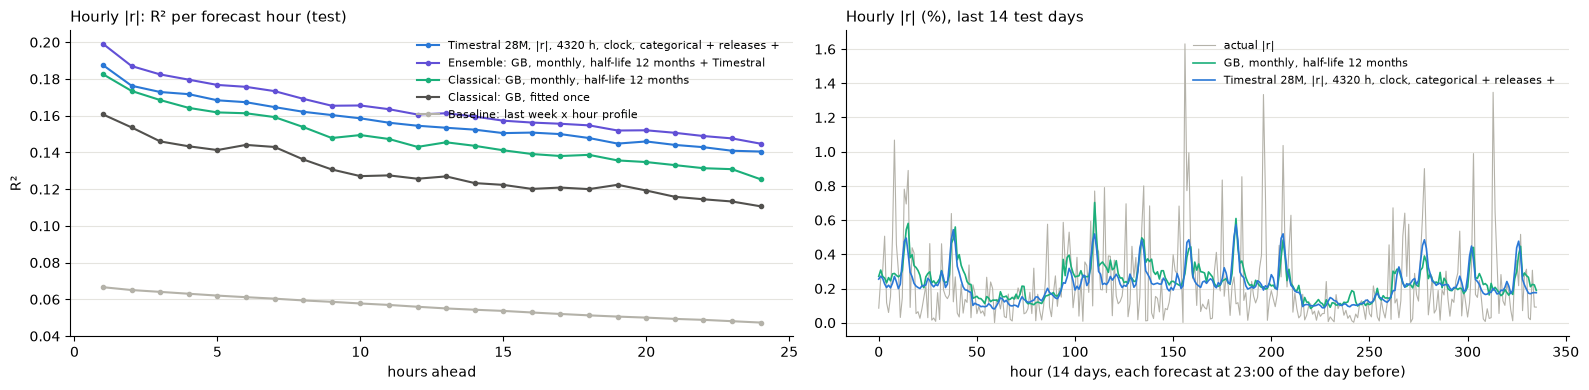

In [10]:
t0 = time.time()
q_test = timestral_quantiles(P["test"], TS["series"], TS["ctx"], TS["covs"], TS["repo"])
e_test = expected_abs(q_test).reshape(-1)
if TS_RESCALE:
    lin_tv = LinearRegression().fit(np.r_[TS["e"]["cal"], TS["e"]["val"]][:, None], np.r_[ya["cal"], ya["val"]])
    abs_val[TS_NAME] = TS["lin"].predict(TS["e"]["val"][:, None])
    abs_test[TS_NAME] = lin_tv.predict(e_test[:, None])
    print(f"rescaling refitted on train + validation: a {lin_tv.intercept_:+.3f}, b {lin_tv.coef_[0]:.3f}")
else:
    abs_val[TS_NAME], abs_test[TS_NAME] = TS["e"]["val"], e_test
print(f"test forecast: {len(P['test']):,} origins in {time.time() - t0:.0f} s")

# for reference only, not a candidate: the best setting with the covariates of the first run (cached forecasts)
OLD_COVS = ("clock, categorical", "clock, numeric", "releases", "range, volume")
ts_old = run_variant(TS["series"], TS["ctx"], tuple(g for g in TS["covs"] if g in OLD_COVS), TS["repo"])
TS_OLD = "For reference: Timestral without the new covariates"
if ts_old is not TS:
    abs_val[TS_OLD] = ts_old["e"]["val"]
    abs_test[TS_OLD] = expected_abs(timestral_quantiles(P["test"], ts_old["series"], ts_old["ctx"], ts_old["covs"], ts_old["repo"])).reshape(-1)

ENS = {f"Ensemble: {r.split(': ')[1]} + Timestral": [r, TS_NAME] for r in REFS}
for e, members in ENS.items():
    abs_val[e] = np.mean([abs_val[m] for m in members], axis=0)
    abs_test[e] = np.mean([abs_test[m] for m in members], axis=0)

abs_tab = pd.DataFrame.from_dict({k: {"val R2": U.r2(ya["val"], abs_val[k]), "test R2": U.r2(ya["test"], v),
                                       "test MAE": mean_absolute_error(ya["test"], v), "test corr": safe_corr(v, ya["test"])}
                                   for k, v in abs_test.items()}, orient="index")
with pd.option_context("display.max_colwidth", 70):
    display(abs_tab.round(4))
CANDIDATES = [TS_NAME] + list(ENS)
TS_CHOSEN = abs_tab.loc[CANDIDATES, "val R2"].idxmax()
REF_BEST = abs_tab.loc[REFS, "val R2"].idxmax()
print(f"chosen on validation: {TS_CHOSEN}")
print(f"best classical reference on validation: {REF_BEST}")
print(f"test R2: {abs_tab.loc[TS_CHOSEN, 'test R2']:.4f} against {abs_tab.loc[REF_BEST, 'test R2']:.4f} "
      f"({abs_tab.loc[TS_CHOSEN, 'test R2'] - abs_tab.loc[REF_BEST, 'test R2']:+.4f})")

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ac = ya["test"].reshape(-1, 24)
lines = [(TS_NAME, BLUE)] + [(k, c) for k, c in [(GB_REFIT, AQUA), (GB_ABS, INK)] if k in abs_test] + [(RULE, GREY)]
if TS_CHOSEN != TS_NAME:
    lines.insert(1, (TS_CHOSEN, PURPLE))
for k, c in lines:
    pr = abs_test[k].reshape(-1, 24)
    ax[0].plot(range(1, 25), [U.r2(ac[:, j], pr[:, j]) for j in range(24)], "o-", ms=3, color=c, label=k[:60])
ax[0].set_xlabel("hours ahead")
ax[0].set_ylabel("R²")
ax[0].legend(frameon=False, fontsize=8)
tidy(ax[0], "Hourly |r|: R² per forecast hour (test)")
seg = test_days[-14:]                                                # last 14 days, one origin per day
ax[1].plot(np.abs(Y["test"][seg]).reshape(-1), lw=0.8, color=GREY, label="actual |r|")
ax[1].plot(abs_test[REF_BEST].reshape(-1, 24)[seg].reshape(-1), lw=1.2, color=AQUA, label=REF_BEST[11:])
ax[1].plot(abs_test[TS_NAME].reshape(-1, 24)[seg].reshape(-1), lw=1.2, color=BLUE, label=TS_NAME[:60])
ax[1].set_xlabel("hour (14 days, each forecast at 23:00 of the day before)")
ax[1].legend(frameon=False, fontsize=8)
tidy(ax[1], "Hourly |r| (%), last 14 test days")
plt.tight_layout()
plt.show()

SUMMARY.append({"question": "size of each of the next 24 hours (|r|)", "Timestral (chosen without the test)": TS_CHOSEN,
                "test result": f"R2 {abs_tab.loc[TS_CHOSEN, 'test R2']:.3f} (Timestral alone {abs_tab.loc[TS_NAME, 'test R2']:.3f})",
                "classical reference (refitted here)": "; ".join(f"{k[11:]}: R2 {abs_tab.loc[k, 'test R2']:.3f}" for k in REFS)})

### 3.4 Timestral as a feature of Gradient Boosting

The averages of 3.3 give Timestral and Gradient Boosting the same weight in every hour. Here Timestral's forecast enters Gradient Boosting as extra columns instead, so the trees can learn when to trust it: release hours, calm or wild periods, hours ahead. Nothing of Timestral is trained. Its forecast, with the setting chosen in 3.2, is computed at every train and pool origin too (cached), and Gradient Boosting is fitted exactly as in 3.1, with the same setting.

**Columns**, added to base + B3, chosen by the validation R² of Gradient Boosting fitted once on train:

- Timestral's **mean \|r\|** (section 2);
- the mean and **all 21 quantiles** of the forecast: its whole distribution, spread and tails included;
- the **GARCH** forecast of section 1.4, the expected volatility of a second model;
- and their combinations.

The chosen columns are then used fitted once and refitted every month, as the references are. The final choice is made on validation, among these two stacked models, the average of the monthly stacked model with Timestral, and the candidates of 3.3.

**Caveat.** The earliest train origins (2020) have less than 180 days of history, so there Timestral reads a shorter context than at validation and test.

In [11]:
t0 = time.time()
# Timestral's forecasts (setting of 3.2) at every origin Gradient Boosting reads: validation and test are already
# forecast; the train and pool origins are added here (cached)
if "pool" not in P:
    pool = np.arange(len(origins))[::STRIDE]
    P["pool"], Y["pool"], D["pool"] = pos_all[pool], y_all[pool], origins[pool]
done = np.r_[P["val"], P["test"]]
extra = np.setdiff1d(np.r_[P["pool"], P["train"]], done)
q_extra = timestral_quantiles(extra, TS["series"], TS["ctx"], TS["covs"], TS["repo"])
_p = np.r_[extra, done]
_o = np.argsort(_p, kind="stable")
TSQ_POS, TSQ = _p[_o], np.concatenate([q_extra, TS["q"]["val"], q_test])[_o]
print(f"Timestral forecasts for {len(extra):,} train and pool origins ({time.time() - t0:.0f} s)")


def ts_cols(block, parts):
    # extra long-format columns of a block: Timestral's mean |r|, its 21 quantiles, the GARCH forecast
    i = np.searchsorted(TSQ_POS, P[block])
    assert (TSQ_POS[i] == P[block]).all()
    q = TSQ[i]
    cols = {"mean": expected_abs(q).reshape(-1, 1), "quantiles": q.reshape(-1, len(LEVELS)),
            "garch": garch_abs(block)[:, None]}
    return np.hstack([cols[k] for k in parts])


def XS(block, parts):
    base = XA[block] if block in XA else Xl(block, BASE, H_BASE + B3)
    return np.hstack([base, ts_cols(block, parts)])


FSETS = {"+ Timestral mean": ("mean",),
         "+ Timestral mean and 21 quantiles": ("mean", "quantiles"),
         f"+ {GARCH_CHOSEN}": ("garch",),
         f"+ Timestral mean + {GARCH_CHOSEN}": ("mean", "garch"),
         f"+ Timestral mean and 21 quantiles + {GARCH_CHOSEN}": ("mean", "quantiles", "garch")}
fs_val = {"base + B3 (reference)": U.r2(ya["val"], abs_val[GB_ABS])}
for name, parts in FSETS.items():
    m = fit_cached(f"stacked GB, base + B3 {name}, train", make_best, XS("train", parts), ya["train"])
    fs_val[name] = U.r2(ya["val"], m.predict(XS("val", parts)))
fs_tab = pd.Series(fs_val, name="val R2, GB fitted once on train").sort_values(ascending=False)
display(fs_tab.round(4).to_frame())
FS_NAME = fs_tab.drop("base + B3 (reference)").idxmax()
FS = FSETS[FS_NAME]
print(f"columns chosen on validation: base + B3 {FS_NAME}")

# the chosen columns, fitted once and refitted every month
STACK_ONCE, STACK_REFIT = "Stacked: GB fitted once + Timestral", "Stacked: GB monthly, half-life 12 months + Timestral"
stack_once = fit_cached(f"{STACK_ONCE}, {FS_NAME}, train + validation", make_best, XS("tv", FS), ya["tv"])   # export (3.7)
stack_train = fit_cached(f"stacked GB, base + B3 {FS_NAME}, train", make_best, XS("train", FS), ya["train"])   # loaded
abs_val[STACK_ONCE], abs_test[STACK_ONCE] = stack_train.predict(XS("val", FS)), stack_once.predict(XS("test", FS))
STACKED, ENS_STACK = [STACK_ONCE], {}
if RUN_GB_REFIT:
    XS_pool = XS("pool", FS)
    for b, store in (("val", abs_val), ("test", abs_test)):
        key = ("gb_refit_stacked", b, tuple(sorted(p_abs_gb.items())), tuple(B3), FS, GARCH_CHOSEN, TS_NAME, 12,
               digest(P[b]), str(hourly.index[-1]))
        store[STACK_REFIT] = cached(key, lambda: refit_monthly(b, XS(b, FS), Xp=XS_pool))
    STACKED.append(STACK_REFIT)
    ENS_STACK = {"Ensemble: stacked GB monthly + Timestral": [STACK_REFIT, TS_NAME]}
for e, members in ENS_STACK.items():
    abs_val[e] = np.mean([abs_val[m] for m in members], axis=0)
    abs_test[e] = np.mean([abs_test[m] for m in members], axis=0)
ENS.update(ENS_STACK)

# which columns the stacked model uses: drop in validation R2 when a group of columns is shuffled
X_va_s = XS("val", FS)
groups_s = {"base + B3": np.arange(XA["val"].shape[1])}
col = XA["val"].shape[1]
for part, width in (("mean", 1), ("quantiles", len(LEVELS)), ("garch", 1)):
    if part in FS:
        groups_s[{"mean": "Timestral mean", "quantiles": "Timestral quantiles", "garch": GARCH_CHOSEN}[part]] = np.arange(col, col + width)
        col += width
r2_full = U.r2(ya["val"], stack_train.predict(X_va_s))
imp = {}
for gname, cols_ in groups_s.items():
    drops = []
    for rep in range(3):
        Xp_ = X_va_s.copy()
        Xp_[:, cols_] = Xp_[np.random.default_rng(rep).permutation(len(Xp_))][:, cols_]
        drops.append(r2_full - U.r2(ya["val"], stack_train.predict(Xp_)))
    imp[gname] = np.mean(drops)
display(pd.Series(imp, name="drop in val R2 when shuffled").round(4).to_frame())

abs_tab = pd.DataFrame.from_dict({k: {"val R2": U.r2(ya["val"], abs_val[k]), "test R2": U.r2(ya["test"], v),
                                       "test MAE": mean_absolute_error(ya["test"], v), "test corr": safe_corr(v, ya["test"])}
                                   for k, v in abs_test.items()}, orient="index")
short = lambda k: k.split(": ", 1)[1]                                # name without its family
PREV_CHOSEN = TS_CHOSEN                                              # the choice of 3.3
CANDIDATES = CANDIDATES + STACKED + list(ENS_STACK)
TS_CHOSEN = abs_tab.loc[CANDIDATES, "val R2"].idxmax()
with pd.option_context("display.max_colwidth", 70):
    display(abs_tab.loc[[RULE, GARCH_NAME] + REFS + CANDIDATES].round(4))

# release hours: R2 on those rows and mean forecast / mean actual (below 1 = under-predicted)
rel_v, rel_t = release_rows("val"), release_rows("test")
rel_tab = pd.DataFrame({k: {"val: R2 release hours": U.r2(ya["val"][rel_v], abs_val[k][rel_v]),
                            "val: forecast / actual": abs_val[k][rel_v].mean() / ya["val"][rel_v].mean(),
                            "test: R2 release hours": U.r2(ya["test"][rel_t], abs_test[k][rel_t]),
                            "test: forecast / actual": abs_test[k][rel_t].mean() / ya["test"][rel_t].mean()}
                        for k in dict.fromkeys([REF_BEST, TS_NAME, PREV_CHOSEN] + STACKED + [TS_CHOSEN])}).T
print(f"release hours: {rel_v.sum()} validation rows, {rel_t.sum()} test rows")
with pd.option_context("display.max_colwidth", 70):
    display(rel_tab.round(3))
print(f"chosen on validation among all candidates: {TS_CHOSEN}")
print(f"test R2: {abs_tab.loc[TS_CHOSEN, 'test R2']:.4f} against {abs_tab.loc[REF_BEST, 'test R2']:.4f} for {REF_BEST} "
      f"({abs_tab.loc[TS_CHOSEN, 'test R2'] - abs_tab.loc[REF_BEST, 'test R2']:+.4f}) ({time.time() - t0:.0f} s)")

LABEL = {STACK_ONCE: "stacked GB, fitted once", STACK_REFIT: "stacked GB, monthly"}
others = [f"Timestral alone {abs_tab.loc[TS_NAME, 'test R2']:.3f}"] + [f"{LABEL.get(k, short(k))} {abs_tab.loc[k, 'test R2']:.3f}"
                                                                     for k in dict.fromkeys([PREV_CHOSEN] + STACKED) if k != TS_CHOSEN]
SUMMARY[0].update({"Timestral (chosen without the test)": TS_CHOSEN,
                   "test result": f"R2 {abs_tab.loc[TS_CHOSEN, 'test R2']:.3f} ({'; '.join(others)})"})

Timestral forecasts for 4,299 train and pool origins (0 s)


,"val R2, GB fitted once on train"
"+ Timestral mean + GARCH(1,1)",0.1168
"+ Timestral mean and 21 quantiles + GARCH(1,1)",0.1153
+ Timestral mean,0.1151
+ Timestral mean and 21 quantiles,0.1143
base + B3 (reference),0.0947
"+ GARCH(1,1)",0.0935


columns chosen on validation: base + B3 + Timestral mean + GARCH(1,1)


,drop in val R2 when shuffled
base + B3,0.0307
Timestral mean,0.1317
"GARCH(1,1)",0.0001


,val R2,test R2,test MAE,test corr
Baseline: last week x hour profile,0.0497,0.0560,0.2345,0.2442
"Baseline: GARCH(1,1) x hour profile",0.0051,0.0381,0.2576,0.2673
"Classical: GB, fitted once",0.0947,0.1295,0.2220,0.3613
"Classical: GB, monthly, half-life 12 months",0.1005,0.1479,0.2208,0.3859
"Timestral 28M, |r|, 4320 h, clock, categorical + releases + range, volume + ETH size + VIX",0.1208,0.1568,0.2175,0.3963
"Ensemble: GB, fitted once + Timestral",0.1209,0.1589,0.2177,0.3989
"Ensemble: GB, monthly, half-life 12 months + Timestral",0.1215,0.1641,0.2175,0.4053
Stacked: GB fitted once + Timestral,0.1168,0.1553,0.2187,0.3953
"Stacked: GB monthly, half-life 12 months + Timestral",0.1112,0.1571,0.2187,0.3987
Ensemble: stacked GB monthly + Timestral,0.1210,0.1638,0.2172,0.4050


release hours: 288 validation rows, 2568 test rows


,val: R2 release hours,val: forecast / actual,test: R2 release hours,test: forecast / actual
"Classical: GB, monthly, half-life 12 months",-0.226,0.421,-0.099,0.660
"Timestral 28M, |r|, 4320 h, clock, categorical + releases + range, volume + ETH size + VIX",-0.045,0.653,-0.014,0.804
"Ensemble: GB, monthly, half-life 12 months + Timestral",-0.097,0.537,-0.035,0.732
Stacked: GB fitted once + Timestral,-0.066,0.573,-0.029,0.749
"Stacked: GB monthly, half-life 12 months + Timestral",-0.089,0.597,-0.032,0.760


chosen on validation among all candidates: Ensemble: GB, monthly, half-life 12 months + Timestral
test R2: 0.1641 against 0.1479 for Classical: GB, monthly, half-life 12 months (+0.0162) (7 s)


### 3.5 How sure are we?

The moving-block bootstrap of `neural-models.ipynb` (section 7): the 829 independent test days are resampled in blocks of 10 days, 1,000 times, each day bringing its 24 test origins. A difference whose 95% interval does not include 0 is reliable.

In [12]:
def day_orig(idx):
    # all test origins of the chosen independent days (the last day may be incomplete)
    o = (test_days[idx][:, None] + np.arange(24)).ravel()
    return o[o < len(P["test"])]


days_rows = lambda idx: rows24(day_orig(idx))                        # their 24 long-format rows each
r2_days = lambda pred, i: U.r2(ya["test"][days_rows(i)], pred[days_rows(i)])
diff_days = lambda a, b: (lambda i: r2_days(abs_test[a], i) - r2_days(abs_test[b], i))
boot_stats = {f"hourly |r| R², {TS_CHOSEN}": lambda i: r2_days(abs_test[TS_CHOSEN], i)}
for ref in REFS:
    boot_stats[f"{TS_NAME} − {short(ref)}"] = diff_days(TS_NAME, ref)
for e in ENS:
    boot_stats[f"{e} − {short(ENS[e][0])}"] = diff_days(e, ENS[e][0])
for s in STACKED:
    boot_stats[f"{s} − {short(REF_BEST)}"] = diff_days(s, REF_BEST)
if TS_CHOSEN != PREV_CHOSEN:
    boot_stats[f"{TS_CHOSEN} − {PREV_CHOSEN}"] = diff_days(TS_CHOSEN, PREV_CHOSEN)
boot_rows = {}
for name, fn in boot_stats.items():
    b = U.block_bootstrap(fn, ND, n_boot=1000, block=10, seed=RANDOM_STATE)
    boot_rows[name] = {"estimate": fn(np.arange(ND)), "CI 2.5%": np.percentile(b, 2.5), "CI 97.5%": np.percentile(b, 97.5),
                       "share of resamples > 0": (b > 0).mean()}
with pd.option_context("display.max_colwidth", 90):
    display(pd.DataFrame(boot_rows).T.round(4))

,estimate,CI 2.5%,CI 97.5%,share of resamples > 0
"hourly |r| R², Ensemble: GB, monthly, half-life 12 months + Timestral",0.1641,0.1421,0.1872,1.000
"Timestral 28M, |r|, 4320 h, clock, categorical + releases + range, volume + ETH size + VIX − GB, fitted once",0.0273,0.0192,0.0354,1.000
"Timestral 28M, |r|, 4320 h, clock, categorical + releases + range, volume + ETH size + VIX − GB, monthly, half-life 12 months",0.0089,0.0023,0.0162,0.994
"Ensemble: GB, fitted once + Timestral − GB, fitted once",0.0294,0.0244,0.0346,1.000
"Ensemble: GB, monthly, half-life 12 months + Timestral − GB, monthly, half-life 12 months",0.0162,0.0128,0.0198,1.000
"Ensemble: stacked GB monthly + Timestral − GB monthly, half-life 12 months + Timestral",0.0067,0.0032,0.0097,1.000
"Stacked: GB fitted once + Timestral − GB, monthly, half-life 12 months",0.0074,0.0008,0.0133,0.988
"Stacked: GB monthly, half-life 12 months + Timestral − GB, monthly, half-life 12 months",0.0092,0.0038,0.0146,0.999


### 3.6 What we see

**Answer: yes. Timestral 28M, used zero-shot, has test R² 0.157, reliably above Gradient Boosting refitted every month (0.148): +0.009, interval [+0.002, +0.016], better in 99.4% of the resamples. The candidate chosen on validation, its plain average with that Gradient Boosting, reaches 0.164: +0.016, interval [+0.013, +0.020]. Feeding Timestral's forecast into Gradient Boosting as a column (3.4) is worse than that average.**

| Model | val R² | test R² |
|---|---|---|
| Last week × hour profile | 0.0497 | 0.0560 |
| GARCH(1,1) × hour profile (section 1.4) | 0.0051 | 0.0381 |
| Gradient Boosting, fitted once / refitted monthly | 0.0947 / 0.1005 | 0.1295 / 0.1479 |
| Timestral 28M, \|r\|, 180 days, clock + releases + range and volume + ETH size + VIX | 0.1208 | 0.1568 |
| *the same without ETH size and VIX (the setting of the first run; for reference)* | *0.1199* | *0.1570* |
| Average with Gradient Boosting fitted once / refitted monthly (**chosen**) | 0.1209 / **0.1215** | 0.1589 / **0.1641** |
| Stacked: Gradient Boosting + Timestral's mean + GARCH, fitted once / refitted monthly | 0.1168 / 0.1112 | 0.1553 / 0.1571 |
| Average of the monthly stacked model with Timestral | 0.1210 | 0.1638 |
| *For reference, `neural-models.ipynb`: LSTM fine-tuned monthly / average of three families* | *0.1208 / 0.1197* | *0.1556 / 0.1611* |

- **The model must read the size of the moves.** With the series \|r\| the validation R² is 0.108; with the returns r, and the size taken from the spread of the forecast, only 0.067.
- **More history helps:** 30, 90 and 180 days give 0.088, 0.105 and 0.108, still rising at the longest context tried.
- **Covariates: the release calendar and the range help; the clock and the new market covariates do not.** The clock adds +0.0003 as categories and −0.0003 as numbers: Timestral already finds the hour profile in the context. The release hours add +0.008 and the range and volume of the past hours +0.004. Of the four covariates added in this run, ETH size (+0.0002) and VIX (+0.0007) passed the rule "kept if the validation score improves", while order flow (−0.0008) and GARCH (−0.0005) did not. Their gain is noise: on test the setting without them is as good (0.1570 against 0.1568). The size of ETH's moves and the VIX repeat what Bitcoin's own recent moves already say, as `classical-models.ipynb` found for Gradient Boosting.
- **The rescaling is not needed.** Fitted on the train origins of 2020–2022, a wilder period, it lowers every validation score, so the raw forecast is chosen: its mean \|r\| is already on the right scale.
- **Averages help, stacking does not.** Timestral and Gradient Boosting make different errors: the average with the monthly refit adds +0.016 to Gradient Boosting and +0.007 to Timestral alone. Given Timestral's forecast as a column (3.4), Gradient Boosting leans almost only on it (shuffling it costs 0.132 of validation R², shuffling every base column 0.031, the GARCH column 0.0001), but scores below Timestral alone on validation (0.117 against 0.121) and below the average on test (0.155–0.157 against 0.164). The trees cut Timestral's forecast into steps learnt on 2020–2022, when the moves were larger and the earliest origins had less than 180 days of context, and that mapping does not carry over to the calmer later blocks; refitting every month makes it worse on validation (0.111). Adding all 21 quantiles does not help either (0.114–0.115 against 0.115–0.117 with the mean only): the mean already summarizes them for a squared error.
- **Release hours are still under-predicted, Timestral least.** On the test release hours the mean forecast is 0.80× the actual mean \|r\| for Timestral, 0.75–0.76× for the stacked models, 0.73× for the chosen average and 0.66× for Gradient Boosting refitted monthly.
- **In short, none of the attempts to improve on the plain average works, for three different reasons.** The new covariates of Timestral (ETH, order flow, VIX, GARCH) only add noise: what they carry is already in Bitcoin's own recent moves. Stacking is worse, not equal: Gradient Boosting maps Timestral's forecast with what it learnt on 2020–2022. And the extra columns (21 quantiles, GARCH) are redundant with Timestral's mean. The plain average of Timestral and Gradient Boosting refitted monthly stays the best candidate, on validation and on test.
- **Like every model of the project, Timestral scores higher on test than on validation** (0.121 → 0.157): the test block (mid-2024 to 2026) is easier to forecast.
- **Model size:** in an earlier run the 209M model gave 0.1253 on validation and 0.160 on test (average with Gradient Boosting 0.166), +0.003 over the 28M on test for 7× the time (3.2 h for the test block). It is not worth it on this hardware (section 3.2).

### 3.7 Exporting the models

The models of this section are saved in `EXPORT_DIR/<id>/`, where `<id>` is the name of the candidate chosen on validation (`TS_CHOSEN`) in lower case, so the folder says which model is the best one:

- **`models.joblib`**: a dict `{"best": TS_CHOSEN, "models": {name: model}}` with every model of the table of section 3.3 except the baseline rule:
  - Gradient Boosting fitted once on train + validation (the model scored on test);
  - Gradient Boosting refitted for the month after the data: every pool row, with the half-life of 12 months counted from the last hour (with `RUN_GB_REFIT`);
  - Timestral, as its setting: repo, revision, series, context, covariates and rescaling. Nothing of Timestral is trained here, so its weights are not copied: `TimestralForecaster.from_pretrained(repo, revision=...)` downloads them again;
  - Gradient Boosting with Timestral's forecast as columns (section 3.4), fitted once on train + validation and, with `RUN_GB_REFIT`, refitted for the month after the data. Their columns are base + B3 followed by `metadata.json`'s "stacked columns": Timestral's forecast of the 24 hours (its setting is also in the bundle) and the GARCH forecast;
  - the averages, as the list of the models they average.
- **`metadata.json`**: the id, the best model and its members, the columns and setting of Gradient Boosting, the hour profile used by `tgt_hour_profile`, the data period and the validation and test scores of every exported model.

To load them: `bundle = joblib.load(os.path.join(EXPORT_DIR, EXPORT_ID, "models.joblib"))`, then `bundle["models"][bundle["best"]]`. The Gradient Boosting models read the long-format rows of `Xl(block, BASE, H_BASE + B3)` (section 1.3).


In [13]:
EXPORT_ID = re.sub(r"[^a-z0-9]+", "-", TS_CHOSEN.lower()).strip("-")   # the model chosen on validation names the export
export_path = os.path.join(EXPORT_DIR, EXPORT_ID)
os.makedirs(export_path, exist_ok=True)

ts_spec = {"repo": TS["repo"], "revision": REVISIONS.get(TS["repo"]), "series": TS["series"], "context hours": TS["ctx"],
           "covariates": list(TS["covs"]),
           "rescaling a, b": [float(lin_tv.intercept_), float(lin_tv.coef_[0])] if TS_RESCALE else None}
MODELS = {GB_ABS: gb_once, TS_NAME: ts_spec}
if RUN_GB_REFIT:
    # the monthly refit for the month after the data: every pool row, weighted by its age at the last hour
    w = 0.5 ** ((hourly.index[-1] - pool_origin) / pd.Timedelta(days=30.44) / 12)
    w = np.asarray(w, float)
    MODELS[GB_REFIT] = fit_cached(f"{GB_REFIT}, month after the data", make_best, X_pool, y_pool, w, legacy=earlier(GB_REFIT))
    MODELS[STACK_REFIT] = fit_cached(f"{STACK_REFIT}, {FS_NAME}, month after the data", make_best, XS_pool, y_pool, w)
MODELS[STACK_ONCE] = stack_once
MODELS.update({e: {"average of": members} for e, members in ENS.items()})
assert TS_CHOSEN in MODELS
joblib.dump({"best": TS_CHOSEN, "models": MODELS}, os.path.join(export_path, "models.joblib"))

meta = {"id": EXPORT_ID, "best": TS_CHOSEN, "best members": ENS.get(TS_CHOSEN, [TS_CHOSEN]),
        "target": "|r| (%) of each of the next 24 hours, long format (24 rows per origin, origin-major)",
        "data": [str(hourly.index[0]), str(hourly.index[-1])],
        "gb columns": BASE + H_BASE + B3, "gb setting": p_abs_gb, "hour profile": HOUR_PROFILE.tolist(),
        "timestral": ts_spec,
        "stacked columns": {"set": FS_NAME, "parts": list(FS), "mean": "Timestral mean |r| of the hour (section 2)",
                            "quantiles": [float(l) for l in LEVELS],
                            "garch": {"model": GARCH_CHOSEN, **{k: float(v) for k, v in
                                      zip(("omega", "alpha", "beta"), GARCH[GARCH_CHOSEN]["params"])},
                                      "persistence": float(GARCH[GARCH_CHOSEN]["per"]), "E|z|": float(GARCH[GARCH_CHOSEN]["c"])}},
        "scores": abs_tab.loc[list(MODELS), ["val R2", "test R2", "test MAE"]].round(4).to_dict(orient="index"),
        "exported": pd.Timestamp.now().isoformat(timespec="seconds")}
with open(os.path.join(export_path, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

print(f"exported to {export_path}: {', '.join(MODELS)}")
print(f"best (chosen on validation): {TS_CHOSEN}   test R2 {abs_tab.loc[TS_CHOSEN, 'test R2']:.4f}")

exported to models\ensemble-gb-monthly-half-life-12-months-timestral: Classical: GB, fitted once, Timestral 28M, |r|, 4320 h, clock, categorical + releases + range, volume + ETH size + VIX, Classical: GB, monthly, half-life 12 months, Stacked: GB monthly, half-life 12 months + Timestral, Stacked: GB fitted once + Timestral, Ensemble: GB, fitted once + Timestral, Ensemble: GB, monthly, half-life 12 months + Timestral, Ensemble: stacked GB monthly + Timestral
best (chosen on validation): Ensemble: GB, monthly, half-life 12 months + Timestral   test R2 0.1641


## 4. Hourly prediction ranges

**Question.** Timestral forecasts quantiles directly. Is its 80% range, [q10, q90] of the return of each predicted hour, as honest and as narrow as the one of `classical-models.ipynb` (section 7)?

**To beat.** Gradient Boosting quantile regression (q10, q50, q90 on the long format, base + B3, the setting of `classical-models.ipynb`), refitted here: coverage 77.9% raw and **80.0% with rolling conformal calibration** (30 days), width 0.98%, but only **56% in release hours**. The metrics are those of `classical-models.ipynb`: coverage (should be 80%), width, coverage in the calmest, middle and wildest third of the hours (by `rule_abs`), coverage and width in release hours, and the pinball losses of q10 and q90.

**Timestral.** The quantiles of the return series r, with the context, covariates and model chosen in section 3.2 (if the chosen series was \|r\|, the same setting is run again on r). To keep the run short this section uses every 6th test origin (`Q_STRIDE`; about 79,500 predicted hours), and every range in the table is scored on those same rows. Rolling conformal calibration is applied to it in the same way: the interval becomes centre ± f × half-width, where f is the 80% quantile of \|y − centre\| / half-width over the test hours of the last 30 days whose outcome was known at the start of the day.

As a side result, the **median** of the forecast is a point forecast of the returns, the assigned task: its MAE skill against the zero forecast is printed below.

Validation block (raw ranges; models fitted on train, Timestral as it comes)


,coverage,width %,coverage calm,coverage middle,coverage wild,coverage release hours,width release hours %,pinball q10,pinball q90
Gradient Boosting quantile (raw),0.8008,0.8827,0.7879,0.7960,0.8185,0.4861,1.0820,0.0805,0.0810
Timestral (raw),0.8002,0.9001,0.7943,0.8002,0.8061,0.5868,1.5712,0.0797,0.0808


Test block (every 6th origin)


,coverage,width %,coverage calm,coverage middle,coverage wild,coverage release hours,width release hours %,pinball q10,pinball q90
Baseline: fixed range,0.8762,1.2798,0.9467,0.8829,0.7991,0.6636,1.2798,0.0922,0.0912
Baseline: volatility-scaled,0.7920,0.9555,0.7866,0.7818,0.8075,0.5070,1.0144,0.0861,0.0843
Gradient Boosting quantile (raw),0.7780,0.9186,0.7662,0.7722,0.7954,0.5350,1.1103,0.0827,0.0804
"Gradient Boosting quantile, rolling conformal 30 days",0.7994,0.9816,0.7826,0.7927,0.8229,0.5584,1.1815,0.0828,0.0806
Timestral (raw),0.8032,0.9952,0.8104,0.7923,0.8069,0.6963,1.5193,0.0824,0.0800
"Timestral, rolling conformal 30 days",0.7992,0.9981,0.7931,0.7895,0.8150,0.6986,1.5217,0.0827,0.0803


MAE skill of the median against the zero forecast (assigned task): Timestral -0.0014, Gradient Boosting q50 -0.0007   (3 s)


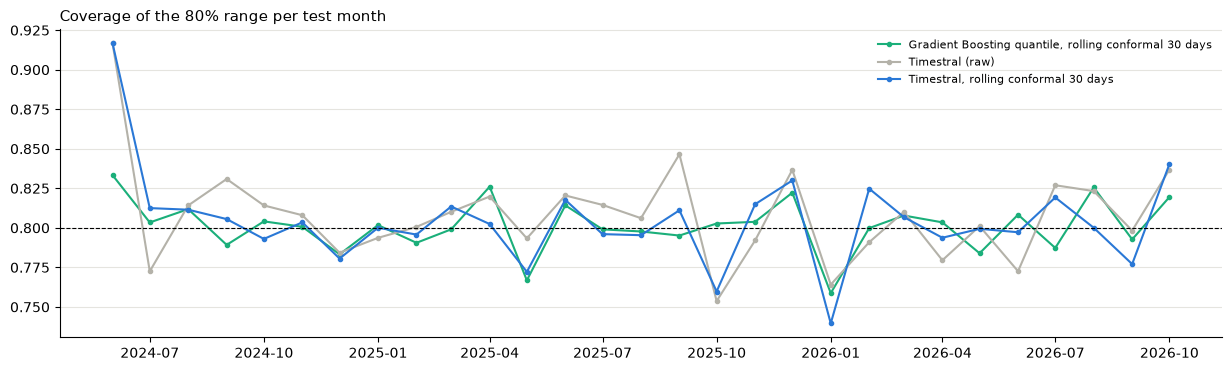

In [14]:
t0 = time.time()
qs = np.arange(0, len(P["test"]), Q_STRIDE)                         # every Q_STRIDE-th test origin: block "tq"
P["tq"], Y["tq"], D["tq"] = P["test"][qs], Y["test"][qs], D["test"][qs]
XA["tq"] = XA["test"][rows24(qs)]
if TS["series"] == "r":
    q_val_r, q_test_r = TS["q"]["val"], q_test[qs]
else:
    q_val_r = timestral_quantiles(P["val"], "r", TS["ctx"], TS["covs"], TS["repo"])
    q_test_r = timestral_quantiles(P["tq"], "r", TS["ctx"], TS["covs"], TS["repo"])
i10, i50, i90 = (int(np.flatnonzero(np.isclose(LEVELS, lv))[0]) for lv in (0.1, 0.5, 0.9))
ts_q = {b: q.reshape(-1, len(LEVELS))[:, [i10, i50, i90]] for b, q in (("val", q_val_r), ("test", q_test_r))}

TAUS = (0.1, 0.5, 0.9)
make_q = lambda tau: HistGradientBoostingRegressor(loss="quantile", quantile=tau, early_stopping=False, max_iter=200,
                                                   learning_rate=0.05, max_depth=3, min_samples_leaf=200, random_state=RANDOM_STATE)
yr = {k: yl(k, "ret") for k in ("train", "val", "tq", "tv")}
q_name = lambda t, rows: f"hourly ranges: GB quantile {t}, {rows}"
gb_q = {"val": np.sort(np.column_stack([fit_cached(q_name(t, "train"), lambda t=t: make_q(t), XA["train"], yr["train"])
                                        .predict(XA["val"]) for t in TAUS]), axis=1),
        "test": np.sort(np.column_stack([save(q_name(t, "train + validation"),
                                              fit_cached(q_name(t, "train + validation"), lambda t=t: make_q(t), XA["tv"], yr["tv"],
                                                         legacy=earlier(q_name(t, "train + validation"))))
                                         .predict(XA["tq"]) for t in TAUS]), axis=1)}


def interval_row(block, lo, hi):
    y, sig, rel = yr[block], rule_abs(block), release_rows(block)
    tercile = pd.qcut(sig, 3, labels=["calm", "middle", "wild"])
    inside = (y >= lo) & (y <= hi)
    return {"coverage": inside.mean(), "width %": (hi - lo).mean(),
            **{f"coverage {c}": inside[tercile == c].mean() for c in ["calm", "middle", "wild"]},
            "coverage release hours": inside[rel].mean(), "width release hours %": (hi - lo)[rel].mean(),
            "pinball q10": U.pinball(y, lo, 0.1), "pinball q90": U.pinball(y, hi, 0.9)}


print("Validation block (raw ranges; models fitted on train, Timestral as it comes)")
display(pd.DataFrame({"Gradient Boosting quantile (raw)": interval_row("val", gb_q["val"][:, 0], gb_q["val"][:, 2]),
                      "Timestral (raw)": interval_row("val", ts_q["val"][:, 0], ts_q["val"][:, 2])}).T.round(4))

# rolling conformal (classical-models.ipynb, section 7): f from the test hours known at the start of each day
y_q = yr["tq"]
known_at = (np.repeat(D["tq"], 24) + pd.to_timedelta(np.tile(np.arange(1, 25), len(D["tq"])), unit="h")).values
test_day = np.repeat(D["tq"].normalize(), 24).values


def rolling_f(centre, half, days_back):
    # f for each test day from the hours whose outcome was known at the start of that day
    score, f = np.abs(y_q - centre) / half, np.ones(len(centre))
    order = np.argsort(known_at)
    k_sorted, s_sorted = known_at[order], score[order]
    for d in np.unique(test_day):
        lo_i, hi_i = np.searchsorted(k_sorted, [d - np.timedelta64(days_back, "D"), d], side="right")
        if hi_i - lo_i >= 24 * 24 * 7 // Q_STRIDE:                   # at least a week of known outcomes; else f = 1
            f[test_day == d] = np.quantile(s_sorted[lo_i:hi_i], 0.8)
    return f


def rolling_conformal(lo, hi, days_back=30):
    centre, half = (lo + hi) / 2, (hi - lo) / 2
    f = rolling_f(centre, half, days_back)
    return centre - f * half, centre + f * half


sigma_tv = np.r_[rule_abs("train"), rule_abs("val")]
fixed, zq = np.quantile(yr["tv"], [0.1, 0.9]), np.quantile(yr["tv"] / sigma_tv, [0.1, 0.9])
sigma_te = rule_abs("tq")
intervals = {"Baseline: fixed range": (np.full(len(y_q), fixed[0]), np.full(len(y_q), fixed[1])),
             "Baseline: volatility-scaled": (sigma_te * zq[0], sigma_te * zq[1]),
             "Gradient Boosting quantile (raw)": (gb_q["test"][:, 0], gb_q["test"][:, 2]),
             "Gradient Boosting quantile, rolling conformal 30 days": rolling_conformal(gb_q["test"][:, 0], gb_q["test"][:, 2]),
             "Timestral (raw)": (ts_q["test"][:, 0], ts_q["test"][:, 2]),
             "Timestral, rolling conformal 30 days": rolling_conformal(ts_q["test"][:, 0], ts_q["test"][:, 2])}
conf_tab = pd.DataFrame({k: interval_row("tq", *v) for k, v in intervals.items()}).T
print(f"Test block (every {Q_STRIDE}th origin)")
display(conf_tab.round(4))
mae_skill = lambda med: 1 - np.abs(y_q - med).mean() / np.abs(y_q).mean()
print(f"MAE skill of the median against the zero forecast (assigned task): Timestral {mae_skill(ts_q['test'][:, 1]):+.4f}, "
      f"Gradient Boosting q50 {mae_skill(gb_q['test'][:, 1]):+.4f}   ({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(15, 4))
month_q = np.repeat(D["tq"].to_period("M"), 24)
for k, c in [("Gradient Boosting quantile, rolling conformal 30 days", AQUA), ("Timestral (raw)", GREY),
             ("Timestral, rolling conformal 30 days", BLUE)]:
    lo, hi = intervals[k]
    cov = pd.Series((y_q >= lo) & (y_q <= hi)).groupby(month_q).mean()
    ax.plot(cov.index.to_timestamp(), cov.values, marker=".", color=c, label=k)
ax.axhline(0.8, c="k", ls="--", lw=0.8)
ax.legend(frameon=False, fontsize=8)
tidy(ax, "Coverage of the 80% range per test month")
plt.show()

best_ts_range = conf_tab.loc["Timestral, rolling conformal 30 days"]
SUMMARY.append({"question": "80% range for each of the next 24 hours", "Timestral (chosen without the test)": "Timestral + rolling conformal (30 days)",
                "test result": f"coverage {best_ts_range['coverage']:.1%}, width {best_ts_range['width %']:.2f}%; "
                               f"release hours {best_ts_range['coverage release hours']:.0%} (raw: coverage {conf_tab.loc['Timestral (raw)', 'coverage']:.1%})",
                "classical reference (refitted here)": "GB quantile + rolling conformal: coverage "
                                                       f"{conf_tab.loc['Gradient Boosting quantile, rolling conformal 30 days', 'coverage']:.1%}, width "
                                                       f"{conf_tab.loc['Gradient Boosting quantile, rolling conformal 30 days', 'width %']:.2f}%; release hours "
                                                       f"{conf_tab.loc['Gradient Boosting quantile, rolling conformal 30 days', 'coverage release hours']:.0%}"})

### 4.1 All 21 quantiles

The 80% range uses 2 of the 21 quantiles. Here the whole forecast distribution is checked, on the same rows:

- **Reliability.** For each level τ, the share of hours that fall below the forecast quantile τ. It should be τ. Shown on validation, test and the release hours of the test.
- **Central ranges** of 50%, 80%, 90% and 98% (q25–q75, q10–q90, q5–q95, q1–q99): coverage and width, overall and in release hours.
- **CRPS** (continuous ranked probability score, the error of the whole distribution; lower is better), approximated by 2 × the pinball loss of the 21 levels, averaged with the weights of section 2. The baselines get all 21 levels too: the fixed quantiles of train + validation, and the same quantiles scaled by `rule_abs`. Gradient Boosting forecasts only three quantiles, so it is not in this table.
- **Release hours, how sure.** The coverage of release hours in section 4 (Timestral against Gradient Boosting + rolling conformal) rests on few hours, so the difference is bootstrapped over test days, as in section 3.5.

Test block (every 6th origin): the whole distribution; 428 release-hour rows


,CRPS,CRPS release hours,50%: coverage,50%: width %,50%: coverage release hours,80%: coverage,80%: width %,80%: coverage release hours,90%: coverage,90%: width %,90%: coverage release hours,98%: coverage,98%: width %,98%: coverage release hours
Timestral,0.2359,0.4452,0.4824,0.4532,0.4112,0.8032,0.9952,0.6963,0.9047,1.4183,0.8341,0.9796,2.5421,0.9486
Baseline: fixed,0.2456,0.4525,0.5825,0.5144,0.3551,0.8762,1.2798,0.6636,0.9499,1.9819,0.8131,0.9934,4.1881,0.9813
Baseline: volatility-scaled,0.2397,0.4656,0.4946,0.4367,0.3505,0.7920,0.9555,0.5070,0.8976,1.4143,0.6963,0.9825,2.8933,0.8855


level,0.01,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,...,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95,0.99
validation,0.011,0.048,0.099,0.152,0.208,0.262,0.314,0.365,0.410,0.454,...,0.539,0.585,0.634,0.687,0.740,0.791,0.845,0.899,0.948,0.989
test,0.010,0.048,0.098,0.150,0.202,0.256,0.309,0.358,0.407,0.454,...,0.543,0.590,0.637,0.686,0.738,0.792,0.846,0.901,0.953,0.990
"test, release hours",0.026,0.091,0.138,0.199,0.241,0.271,0.283,0.318,0.376,0.418,...,0.505,0.537,0.561,0.619,0.682,0.731,0.771,0.834,0.925,0.974
"test, volatility-scaled baseline",0.009,0.052,0.106,0.158,0.207,0.256,0.304,0.351,0.400,0.451,...,0.553,0.603,0.652,0.701,0.751,0.800,0.849,0.898,0.949,0.992


coverage of release hours, Timestral (raw) − GB quantile + rolling conformal: {'estimate': np.float64(0.138), 'CI 2.5%': np.float64(0.079), 'CI 97.5%': np.float64(0.189), 'share of resamples > 0': np.float64(1.0)}


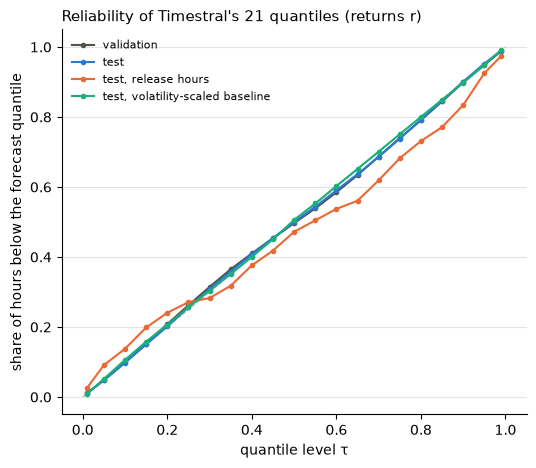

In [15]:
QA = {"val": q_val_r.reshape(-1, len(LEVELS)), "tq": q_test_r.reshape(-1, len(LEVELS))}
rel_tq = release_rows("tq")
q_tv = np.quantile(yr["tv"], LEVELS)
full_q = {"Timestral": QA["tq"],
          "Baseline: fixed": np.tile(q_tv, (len(y_q), 1)),
          "Baseline: volatility-scaled": sigma_te[:, None] * np.quantile(yr["tv"] / sigma_tv, LEVELS)[None, :]}

reliab = pd.DataFrame({"validation": (yr["val"][:, None] <= QA["val"]).mean(axis=0),
                       "test": (y_q[:, None] <= QA["tq"]).mean(axis=0),
                       "test, release hours": (y_q[rel_tq, None] <= QA["tq"][rel_tq]).mean(axis=0),
                       "test, volatility-scaled baseline": (y_q[:, None] <= full_q["Baseline: volatility-scaled"]).mean(axis=0)},
                      index=pd.Index(LEVELS.round(2), name="level"))


def crps(y, q):
    # 2 x the pinball loss over the 21 levels, weighted as the integral over the levels (QW, section 2)
    d = y[:, None] - q
    return 2 * (np.maximum(LEVELS * d, (LEVELS - 1) * d) @ QW).mean()


ranges = {"50%": (0.25, 0.75), "80%": (0.1, 0.9), "90%": (0.05, 0.95), "98%": (0.01, 0.99)}
lv_i = {lv: int(np.flatnonzero(np.isclose(LEVELS, lv))[0]) for pair in ranges.values() for lv in pair}
full_rows = {}
for name, q in full_q.items():
    row = {"CRPS": crps(y_q, q), "CRPS release hours": crps(y_q[rel_tq], q[rel_tq])}
    for rname, (lo, hi) in ranges.items():
        inside = (y_q >= q[:, lv_i[lo]]) & (y_q <= q[:, lv_i[hi]])
        row[f"{rname}: coverage"] = inside.mean()
        row[f"{rname}: width %"] = (q[:, lv_i[hi]] - q[:, lv_i[lo]]).mean()
        row[f"{rname}: coverage release hours"] = inside[rel_tq].mean()
    full_rows[name] = row
full_tab = pd.DataFrame(full_rows).T
print(f"Test block (every {Q_STRIDE}th origin): the whole distribution; {rel_tq.sum()} release-hour rows")
display(full_tab.round(4))
display(reliab.T.round(3))

# release hours: coverage of the 80% range, Timestral (raw) - Gradient Boosting + rolling conformal, by test day
in_rng = {k: (y_q >= intervals[k][0]) & (y_q <= intervals[k][1])
          for k in ("Timestral (raw)", "Gradient Boosting quantile, rolling conformal 30 days")}
days_u, day_of_row = np.unique(test_day, return_inverse=True)
rows_of_day = [np.flatnonzero((day_of_row == d) & rel_tq) for d in range(len(days_u))]


def rel_cov_diff(idx):
    r = np.concatenate([rows_of_day[d] for d in idx])
    return in_rng["Timestral (raw)"][r].mean() - in_rng["Gradient Boosting quantile, rolling conformal 30 days"][r].mean()


b = U.block_bootstrap(rel_cov_diff, len(days_u), n_boot=1000, block=10, seed=RANDOM_STATE)
REL_BOOT = {"estimate": rel_cov_diff(np.arange(len(days_u))), "CI 2.5%": np.percentile(b, 2.5),
            "CI 97.5%": np.percentile(b, 97.5), "share of resamples > 0": (b > 0).mean()}
print("coverage of release hours, Timestral (raw) − GB quantile + rolling conformal:",
      {k: round(v, 3) for k, v in REL_BOOT.items()})

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], color=GREY, lw=0.8, ls="--")
for k, c in (("validation", INK), ("test", BLUE), ("test, release hours", ORANGE), ("test, volatility-scaled baseline", AQUA)):
    ax.plot(LEVELS, reliab[k].values, "o-", ms=3, color=c, label=k)
ax.set_xlabel("quantile level τ")
ax.set_ylabel("share of hours below the forecast quantile")
ax.legend(frameon=False, fontsize=8)
tidy(ax, "Reliability of Timestral's 21 quantiles (returns r)")
plt.show()

### 4.2 What we see

**Answer: as honest and as narrow as the classical range, without any calibration, and reliably better in release hours. The whole distribution is calibrated, not only the 80% range.** On every 6th test origin:

| Range | coverage | width | coverage calm / middle / wild | release hours: coverage, width |
|---|---|---|---|---|
| Gradient Boosting quantile, raw | 77.8% | 0.92% | 76.6% / 77.2% / 79.5% | 53%, 1.11% |
| Gradient Boosting quantile, rolling conformal | 79.9% | 0.98% | 78.3% / 79.3% / 82.3% | 56%, 1.18% |
| **Timestral, raw** | **80.3%** | **1.00%** | 81.0% / 79.2% / 80.7% | **70%, 1.52%** |
| Timestral, rolling conformal | 79.9% | 1.00% | 79.3% / 79.0% / 81.5% | 70%, 1.52% |

- **Timestral's own quantiles are calibrated:** 80.3% coverage on test and 80.0% on validation, as they come. Gradient Boosting needs the rolling conformal step to reach 80%; for Timestral the step changes nothing. Its pinball losses are a little lower (q10 0.0824 against 0.0827, q90 0.0800 against 0.0804).
- **The coverage is even across calm and wild hours** (79–81%), which a useful range needs.
- **All 21 levels are calibrated (4.1).** For every level τ the share of test hours below the forecast quantile is within 1.4 points of τ (4.8% below q5, 50.0% below q50, 95.3% below q95; 1.6 points on validation), and the central ranges of 50%, 90% and 98% cover 48.2%, 90.5% and 98.0%. The volatility-scaled baseline is as well calibrated (0.8 points), but wider where it matters: the CRPS of the whole distribution is 0.236 for Timestral, against 0.240 for that baseline and 0.246 for fixed quantiles.
- **Release hours are the real difference, and it is reliable.** With the release calendar as a known-future covariate, Timestral widens the range of those hours (1.52% against 1.18%) and covers 70% of their moves, against 56% for Gradient Boosting + rolling conformal: +13.8 points, interval [+7.9, +18.9] over 428 release-hour rows, better in every resample. Its CRPS there is 0.445, against 0.466 for the volatility-scaled baseline. It is still too narrow in those hours: 2.6% of them fall below q1 and 2.6% above q99 (1% expected), 9.1% below q5 and 7.5% above q95, and the 50% range covers only 41%. The size of a release move is not known in advance.
- **The median is no better than 0%** (MAE skill −0.0014), like every model of the project: Timestral, too, finds no direction in the hourly returns.

## 5. Conclusions

### 5.1 This run

In [16]:
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(SUMMARY).set_index("question"))
print(f"Total run time: {(time.time() - T_START) / 60:.1f} minutes")

,Timestral (chosen without the test),test result,classical reference (refitted here)
question,,,
size of each of the next 24 hours (|r|),"Ensemble: GB, monthly, half-life 12 months + Timestral","R2 0.164 (Timestral alone 0.157; stacked GB, fitted once 0.155; stacked GB, monthly 0.157)","GB, fitted once: R2 0.130; GB, monthly, half-life 12 months: R2 0.148"
80% range for each of the next 24 hours,Timestral + rolling conformal (30 days),"coverage 79.9%, width 1.00%; release hours 70% (raw: coverage 80.3%)","GB quantile + rolling conformal: coverage 79.9%, width 0.98%; release hours 56%"


Total run time: 2.9 minutes


### 5.2 Conclusions

1. **A pretrained model, used as it comes, beats the models trained on our data** for the size of the hourly moves. Timestral 28M reaches test R² 0.157, reliably above Gradient Boosting refitted every month (0.148) and level with the best network of `neural-models.ipynb` (0.156), which needed hour features, a volume attention mask and monthly fine-tuning. Averaged with Gradient Boosting it reaches 0.164, the best result of the project for this question.
2. **What matters is what the model reads**: the size of the moves rather than the returns, a long context (180 days), and the release calendar as known-future information. The clock adds nothing, since the model finds the hour profile in the context, and neither do ETH, the order flow, the VIX or a GARCH forecast: their validation gains are below 0.001 and vanish on test.
3. **Average it, do not stack it.** Given Timestral's forecast as a column, Gradient Boosting relies almost only on that column but scores below the plain average (test 0.155–0.157 against 0.164): trees learnt on the wilder 2020–2022 hours do not map the forecast well onto the later blocks. Neither the 21 quantiles nor a GARCH forecast as extra columns change this.
4. **A classical volatility model is no substitute.** GARCH fitted by likelihood forecasts the size of the next hours worse than last week's average × the hour profile (validation R² 0.005 against 0.050).
5. **Its whole forecast distribution is honest without calibration**: 80.3% coverage for an 80% range, every one of the 21 quantile levels within 1.4 points, and the lowest CRPS of the ranges tried. Thanks to the release calendar it covers 70% of the release-hour moves, against 56% for the classical ranges, a reliable difference (+13.8 points, interval [+7.9, +18.9]), although it is still too narrow in those hours.
6. **The returns stay unpredictable**: the median of the forecast does not beat 0%, the result of every notebook.
7. **The small model is enough.** The 209M model adds about 0.003 R² on test for 7× the compute. With the 28M the notebook takes under two hours from scratch on a laptop GPU, and a few minutes once the forecasts and models are cached.
8. **The checks hold.** The forecasts do not depend on how origins are batched and do not see the hours after their origin (section 2.1).
9. **The caveat holds.** Timestral was released after our test block and Mistral does not list its real training series. If Bitcoin 2023–2026 is among them, the validation and test results are optimistic. The gains over Gradient Boosting are reliable within this test block, but cannot be called out-of-sample for the model.

### 5.3 Not done here

- **Fine-tuning.** The `timestral` package only forecasts (`forecast` runs under `torch.inference_mode()`), and Mistral offers fine-tuning only through its paid platform. The network itself, `TimestralModel.predict_block`, is a plain PyTorch module, so it can be trained with our own loop: the pinball loss over the 21 quantiles (Timestral's own training loss), a low learning rate, few epochs and early stopping on its own block, possibly only the last layers. Fine-tuned every month, it would be the counterpart of the monthly refits.
- **A forward test** on the hours after Timestral's release (15 Oct 2026), the only block that is out-of-sample for the model whatever its training data; it needs newer data than `data/btc_hourly.csv.gz`.
- **Timestral as a feature of the quantile models**, for the release hours, where its ranges are still too narrow.
- **Next-day volatility** from the same forecast: the expected squared return of each predicted hour, summed over the 24 hours.
- **Longer contexts** (up to 32,768 hours) and the 5M and 123M models.